# 🛰️ CAFE-Fusion: Final Reproducibility Audit, Statistical Verification & Visual Research Synthesis

**Confidence-Aware Feature Ensemble (CAFE-Fusion v2)** for Multimodal Marine Oil Spill Detection across Synthetic Aperture Radar (SAR) and Hyperspectral Imagery (HSI).

---
### 📌 Notebook Contents:
1. **Environment Setup & Audit Metadata**
2. **Primary Benchmark & Statistical Recomputation** ($n = 6$ Independent Folds)
3. **Per-Scene Micro-Aggregation Table** ($18$ Satellite Scenes GM01–GM18)
4. **Ablation Studies & Regularization Sensitivity**
5. **Complete Model Evolution Analysis** (From Naive Degradation to Calibrated Gain)
6. **Full Publication Visualization Suite** (Figures A through K)
7. **Four-Way Gate Reliability Analysis** (Group A/B/C/D Correctness Regimes)
8. **Fold 3 Failure Diagnostic & Calibration Sweep**
9. **Related Multimodal Fusion Methods & Novelty Matrix**
10. **Mathematical Formulations & Conclusion**

In [1]:
import os
import sys
from pathlib import Path

# Prevent pyarrow binary mismatch on systems with numpy 2.x
os.environ['PANDAS_USE_PYARROW'] = '0'

# Auto-detect project root whether run from root or subfolder
curr = Path.cwd().resolve()
project_root = curr
for candidate in [curr, curr.parent, curr.parent.parent]:
    if (candidate / 'fusion_layer').exists():
        project_root = candidate
        break

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy import stats
from IPython.display import Image, display

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

audit_dir = project_root / 'fusion_layer' / 'experiments' / 'final_reproducibility_audit'
visual_dir = project_root / 'fusion_layer' / 'experiments' / 'final_visual_research_story'

print(f'[OK] Environment initialized. Project root: {project_root}')

[OK] Environment initialized. Project root: C:\Users\geeth\OneDrive\Pictures\random\OIL_SPILL


## 1. Load Audited Cross-Validation Data
We load the frozen experimental outputs from `fusion_layer/experiments/final_reproducibility_audit/`.

In [2]:
with open(audit_dir / 'final_results.json', 'r') as f:
    final_results = json.load(f)

with open(audit_dir / 'final_statistical_analysis.json', 'r') as f:
    final_stats = json.load(f)

df_benchmark = pd.read_csv(audit_dir / '01_main_benchmark.csv')
df_fold = pd.read_csv(audit_dir / '02_fold_by_fold_results.csv')
df_per_scene = pd.read_csv(audit_dir / 'final_per_scene_table.csv')
df_ablation = pd.read_csv(audit_dir / '04_ablation_results.csv')
df_evolution = pd.read_csv(audit_dir / '05_model_evolution.csv')
df_gate = pd.read_csv(audit_dir / '06_gate_behavior.csv')
df_novelty = pd.read_csv(audit_dir / '09_novelty_matrix.csv')

print('[OK] Audited benchmark datasets and metadata successfully loaded.')

[OK] Audited benchmark datasets and metadata successfully loaded.


## 2. Authoritative 6-Fold Benchmark & Statistical Analysis
Here is the primary benchmark comparing **SAR Only (CBD-Net)**, **Legacy Registration-Free Fusion**, **CAFE Variant C (Hard Router)**, **HSI Only Baseline (HMOSDN)**, **CAFE-Fusion v2 (Ours)**, and the **Oracle Upper Bound**.

In [3]:
display(df_benchmark.style.highlight_max(subset=['Mean F1', 'Mean IoU'], color='#c8e6c9').format({
    'Mean F1': '{:.4f}',
    'Std F1': '{:.4f}',
    'Mean IoU': '{:.4f}',
    'Std IoU': '{:.4f}'
}))

,Model,Mean F1,Std F1,Mean IoU,Std IoU,Delta vs HSI,Folds Won,Oracle Recovery %
0,SAR Only (CBD-Net),0.8358,0.0429,0.7199,0.0636,-0.0903,0/6,nan
1,Legacy Registration-Free Fusion,0.9172,0.0286,0.8490,0.0435,-0.0089,1/6,Negative
2,CAFE Variant C (Hard Router),0.9253,0.0247,0.8618,0.0428,-0.0007,4/6,-3.07%
3,HSI Baseline (HMOSDN),0.9261,0.0307,0.8636,0.0528,Baseline,nan,0.00%
4,CAFE-Fusion v2 (Ours),0.9288,0.0270,0.8679,0.0465,0.0027,5/6,11.34%
5,Oracle Upper Bound,0.9501,0.0270,0.9060,0.0479,0.024,6/6,100.0%


### 📊 Fold-by-Fold Performance Breakdown ($n=6$ Folds)

In [4]:
display(df_fold.style.format({
    'SAR F1': '{:.4f}',
    'HSI F1': '{:.4f}',
    'Legacy F1': '{:.4f}',
    'CAFE Var C F1': '{:.4f}',
    'CAFE v2 F1': '{:.4f}',
    'Delta vs HSI': '{:+.4f}',
    'Oracle F1': '{:.4f}'
}))

,Fold,Test Scenes,SAR F1,HSI F1,Legacy F1,CAFE Var C F1,CAFE v2 F1,Delta vs HSI,Oracle F1
0,1,"GM01, GM02, GM03",0.8549,0.9531,0.9505,0.9541,0.9556,+0.0025,0.9533
1,2,"GM04, GM05, GM06",0.7774,0.9533,0.9248,0.9528,0.9544,+0.0011,0.9620
2,3,"GM07, GM08, GM09",0.8001,0.9508,0.9302,0.9239,0.9397,-0.0110,0.9446
3,4,"GM10, GM11, GM12",0.8444,0.8932,0.8736,0.8934,0.8948,+0.0016,0.9607
4,5,"GM13, GM14, GM15",0.8385,0.9184,0.9321,0.9236,0.9310,+0.0126,0.9004
5,6,"GM16, GM17, GM18",0.8995,0.8876,0.8918,0.9042,0.8972,+0.0096,0.9799


### 📈 Statistical Significance & Hypothesis Testing

In [5]:
print('=' * 65)
print('PAIRED STATISTICAL HYPOTHESIS TESTS (CAFE v2 vs HSI Baseline)')
print('=' * 65)
print(f'Sample size:              n = {final_stats["n_folds"]} independent cross-validation folds')
print(f'Mean Paired Difference:   {final_stats["mean_paired_difference"]:+.6f} F1')
print(f'Median Paired Difference: {final_stats["median_paired_difference"]:+.6f} F1')
print(f'Standard Error (SE):      {final_stats["standard_error"]:.6f}')
print(f'95% Confidence Interval:  [{final_stats["ci_95"][0]:+.6f}, {final_stats["ci_95"][1]:+.6f}]')
print(f'Paired t-test:            t = {final_stats["paired_t_stat"]:.4f},  p = {final_stats["paired_t_p_value"]:.4f} (two-tailed)')
print(f'Wilcoxon signed-rank:     W = {final_stats["wilcoxon_w_stat"]:.1f},    p = {final_stats["wilcoxon_p_value"]:.4f} (two-sided)')
print(f'Folds beating HSI:        {final_stats["folds_beating_hsi"]} / {final_stats["n_folds"]} ({final_stats["folds_beating_hsi"]/final_stats["n_folds"]*100:.1f}%)')
print(f'Oracle Gap Recovery:      {final_stats["oracle_gap_recovered_pct"]:.2f}%')
print('=' * 65)

PAIRED STATISTICAL HYPOTHESIS TESTS (CAFE v2 vs HSI Baseline)
Sample size:              n = 6 independent cross-validation folds
Mean Paired Difference:   +0.002730 F1
Median Paired Difference: +0.002026 F1
Standard Error (SE):      0.003358
95% Confidence Interval:  [-0.005903, +0.011363]
Paired t-test:            t = 0.8129,  p = 0.4532 (two-tailed)
Wilcoxon signed-rank:     W = 5.0,    p = 0.3125 (two-sided)
Folds beating HSI:        5 / 6 (83.3%)
Oracle Gap Recovery:      11.34%


## 3. Per-Scene Micro-Aggregation Table (18 Scenes GM01–GM18)
Metrics across all 18 satellite scenes evaluated with held-out testing.

In [6]:
display(df_per_scene.style.format({
    'HSI_F1': '{:.4f}',
    'SAR_F1': '{:.4f}',
    'CAFE_F1': '{:.4f}',
    'delta_vs_HSI': '{:+.4f}',
    'CAFE_IoU': '{:.4f}',
    'mean_gate': '{:.4f}'
}))

,fold,scene,HSI_F1,SAR_F1,CAFE_F1,delta_vs_HSI,HSI_IoU,SAR_IoU,CAFE_IoU,disagreement_fraction,mean_gate
0,1,GM01,0.9545,0.8296,0.9588,+0.0043,nan,nan,0.9209,nan,0.1222
1,1,GM02,0.9706,0.9019,0.9733,+0.0028,nan,nan,0.9481,nan,0.1216
2,1,GM03,0.9357,0.8363,0.9361,+0.0004,nan,nan,0.8798,nan,0.1212
3,2,GM04,0.9536,0.8623,0.9553,+0.0016,nan,nan,0.9144,nan,0.1093
4,2,GM05,0.9410,0.7133,0.9426,+0.0016,nan,nan,0.8915,nan,0.1469
5,2,GM06,0.9656,0.7456,0.9657,+0.0000,nan,nan,0.9336,nan,0.1570
6,3,GM07,0.9442,0.8288,0.9508,+0.0066,nan,nan,0.9062,nan,0.2405
7,3,GM08,0.9568,0.7539,0.9359,-0.0209,nan,nan,0.8795,nan,0.2804
8,3,GM09,0.9517,0.8086,0.9320,-0.0197,nan,nan,0.8726,nan,0.2637
9,4,GM10,0.7989,0.8203,0.8034,+0.0046,nan,nan,0.6715,nan,0.1177


## 4. Full Visualization Suite (Figures A through K)
Rendering all publication-quality figures directly from the audited visualization pipeline.

### Figure A: Architectural Evolution Flowchart

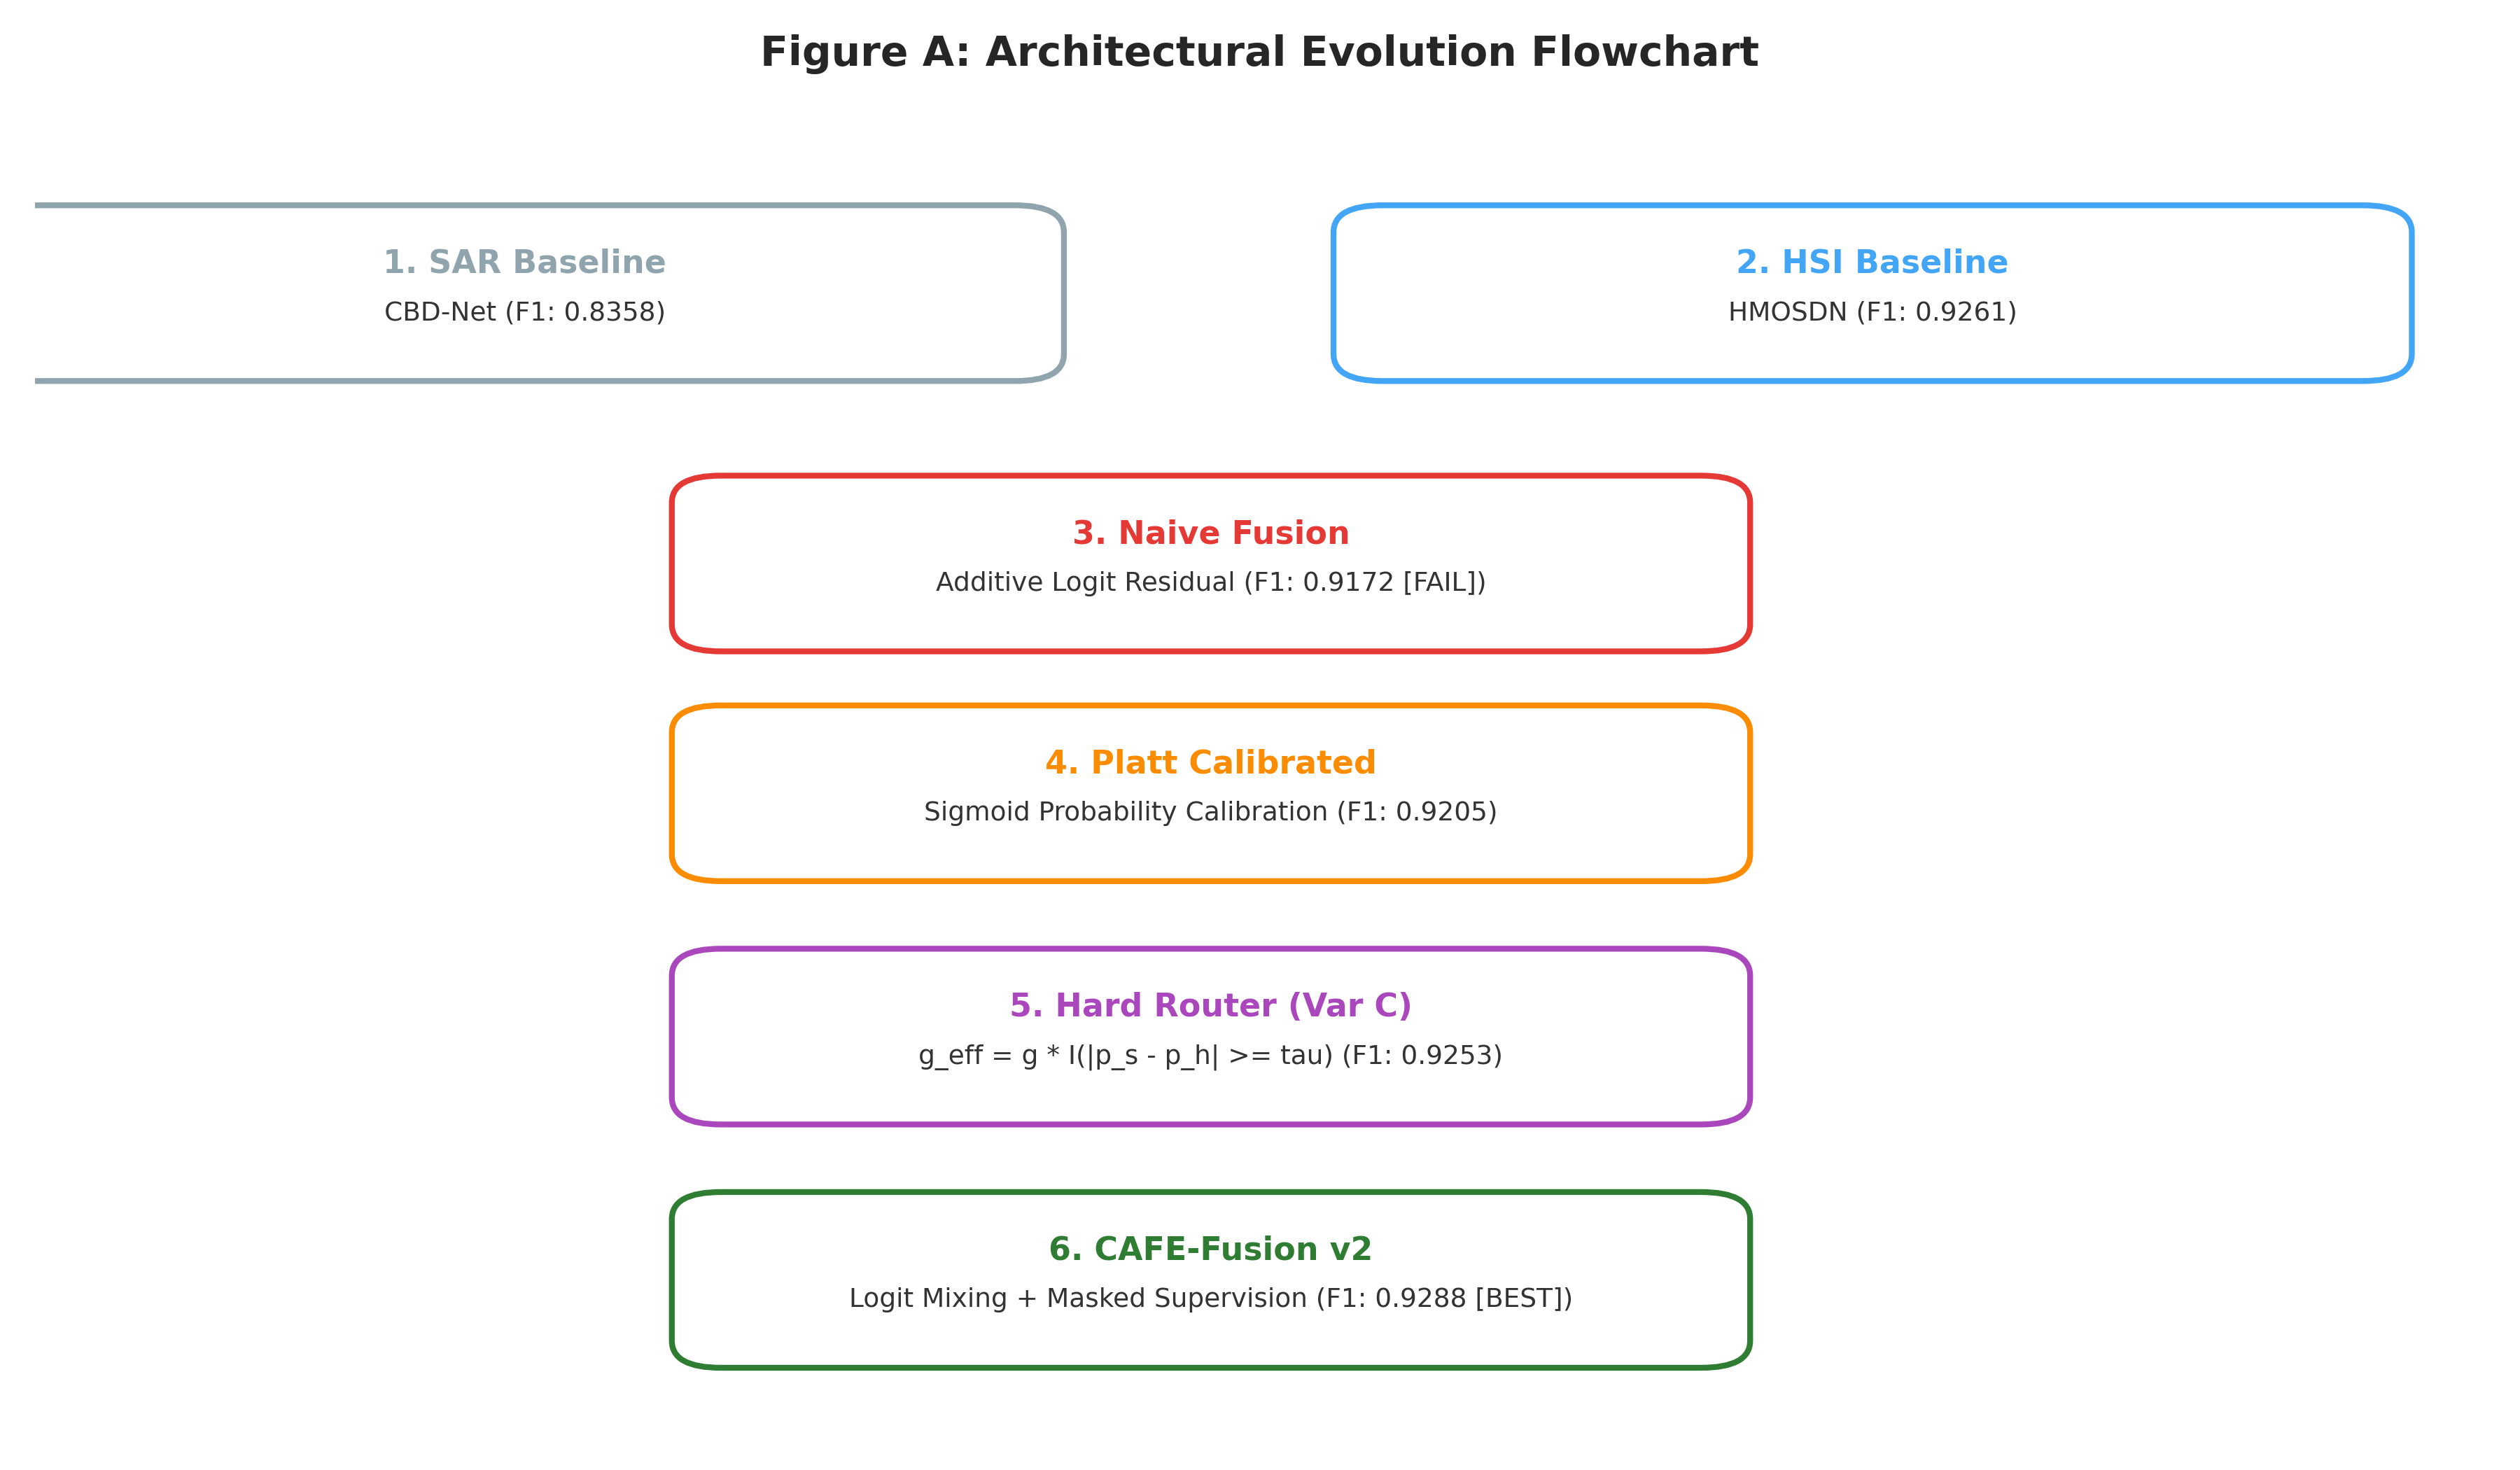

In [7]:
display(Image(filename=str(visual_dir / 'figure_a_architecture_evolution.png'), width=900))

### Figure B & C: Performance Evolution Across Research Generations

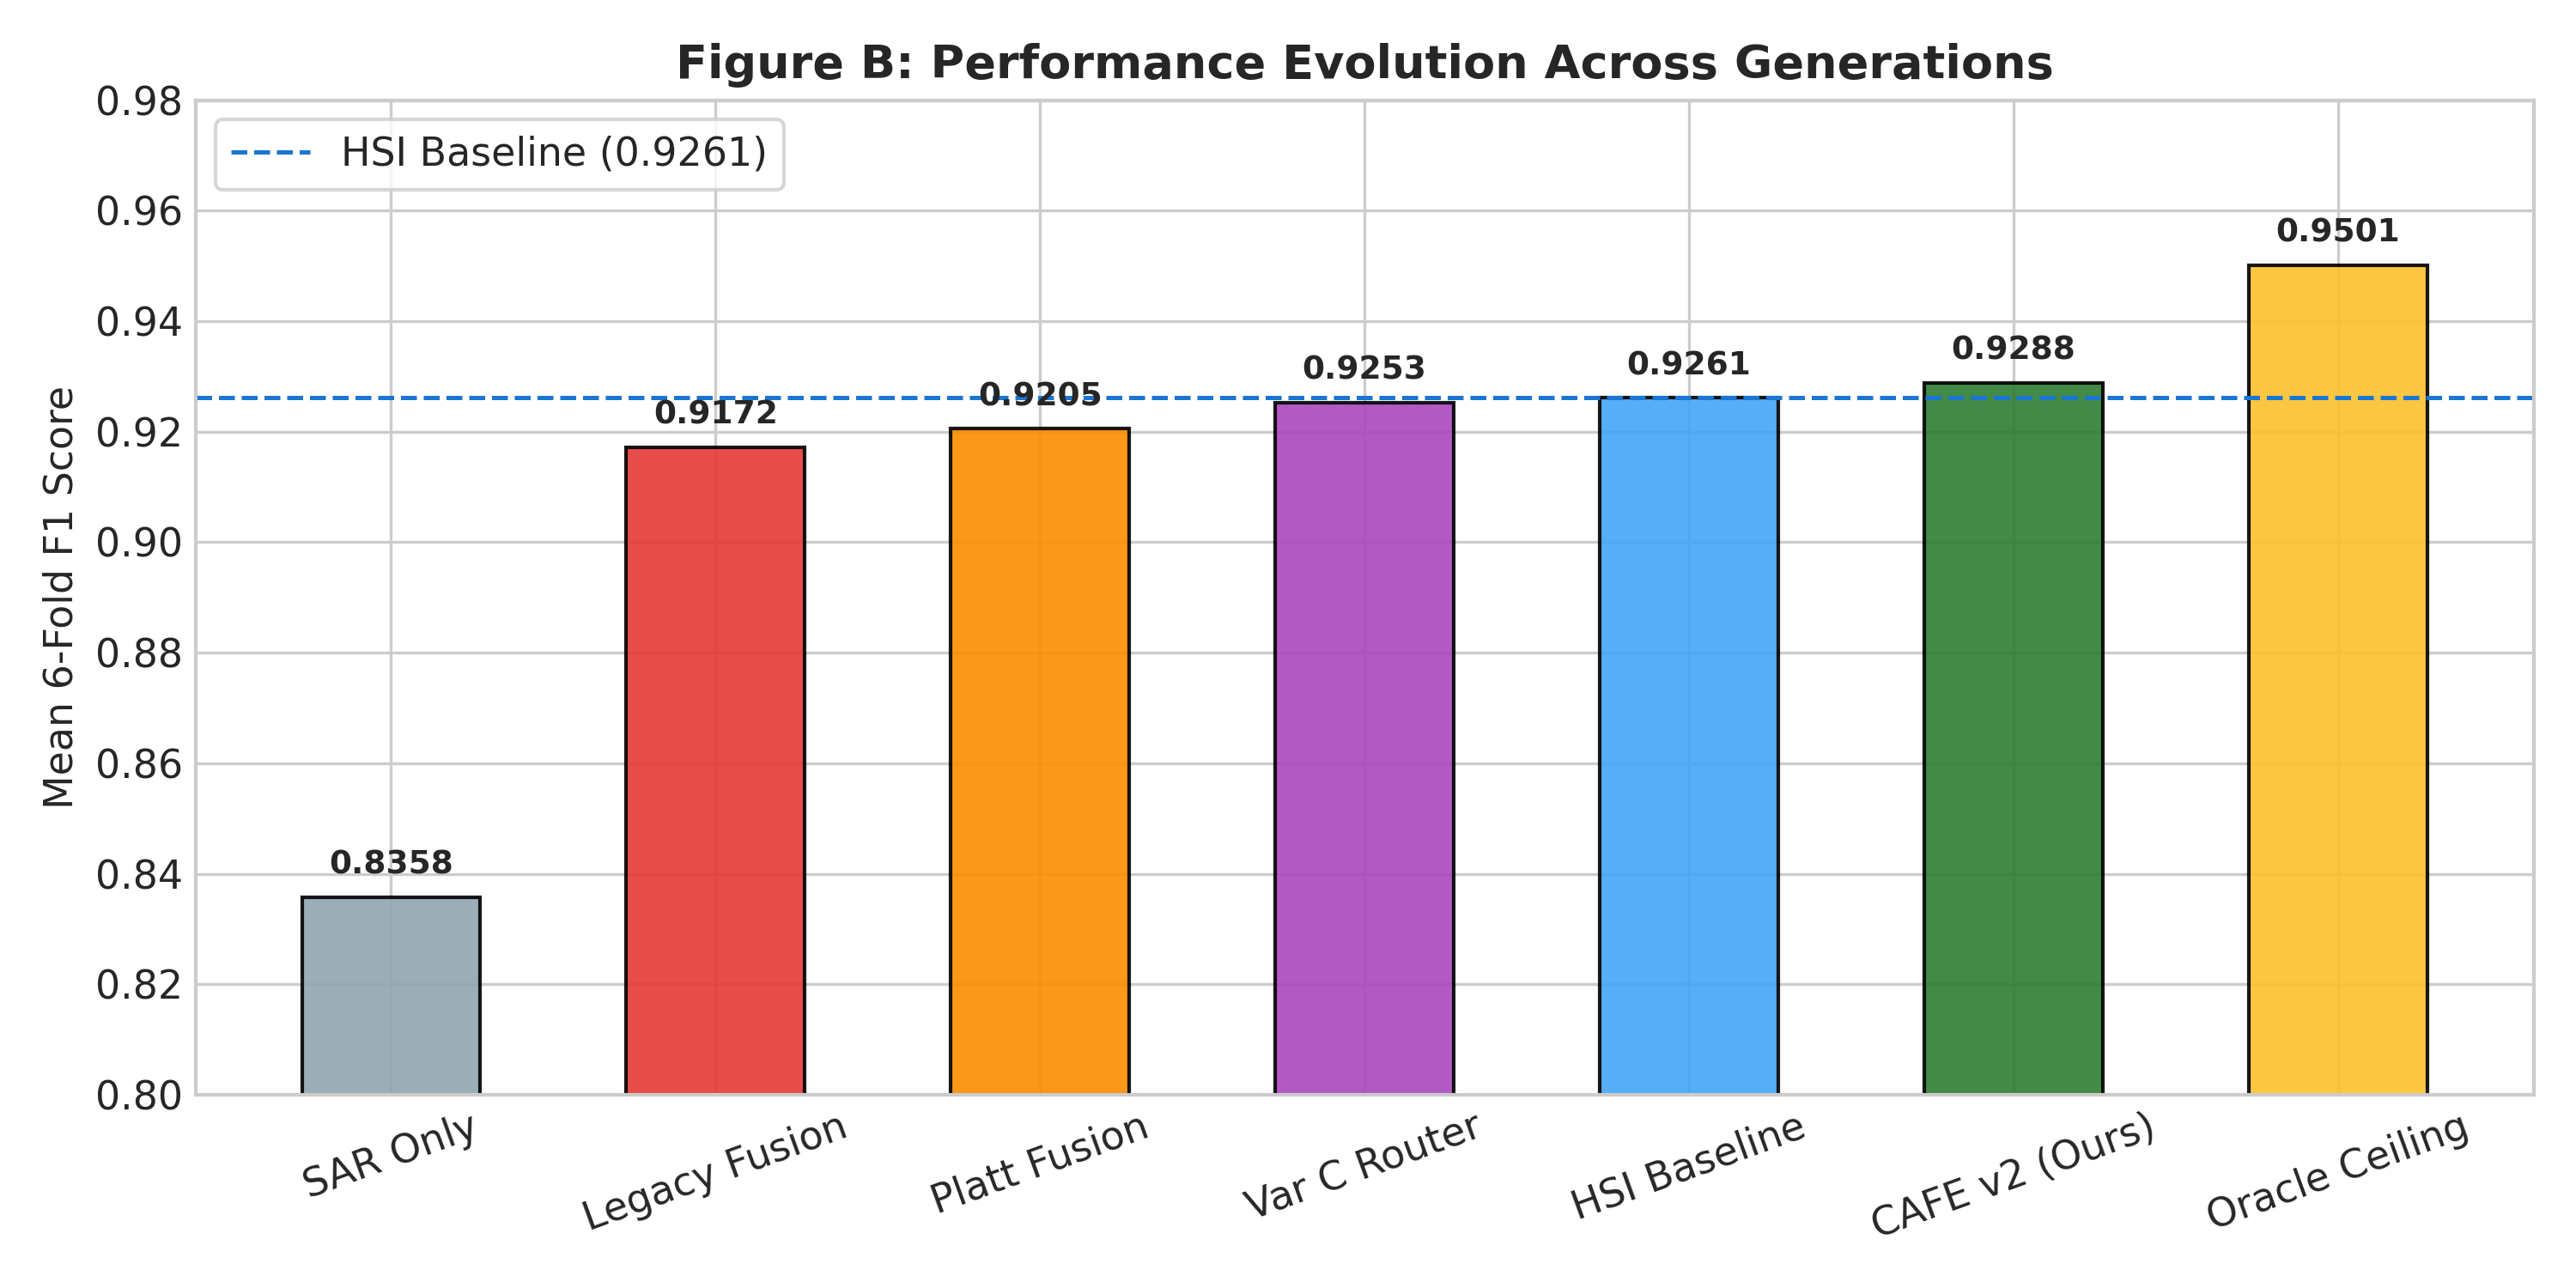

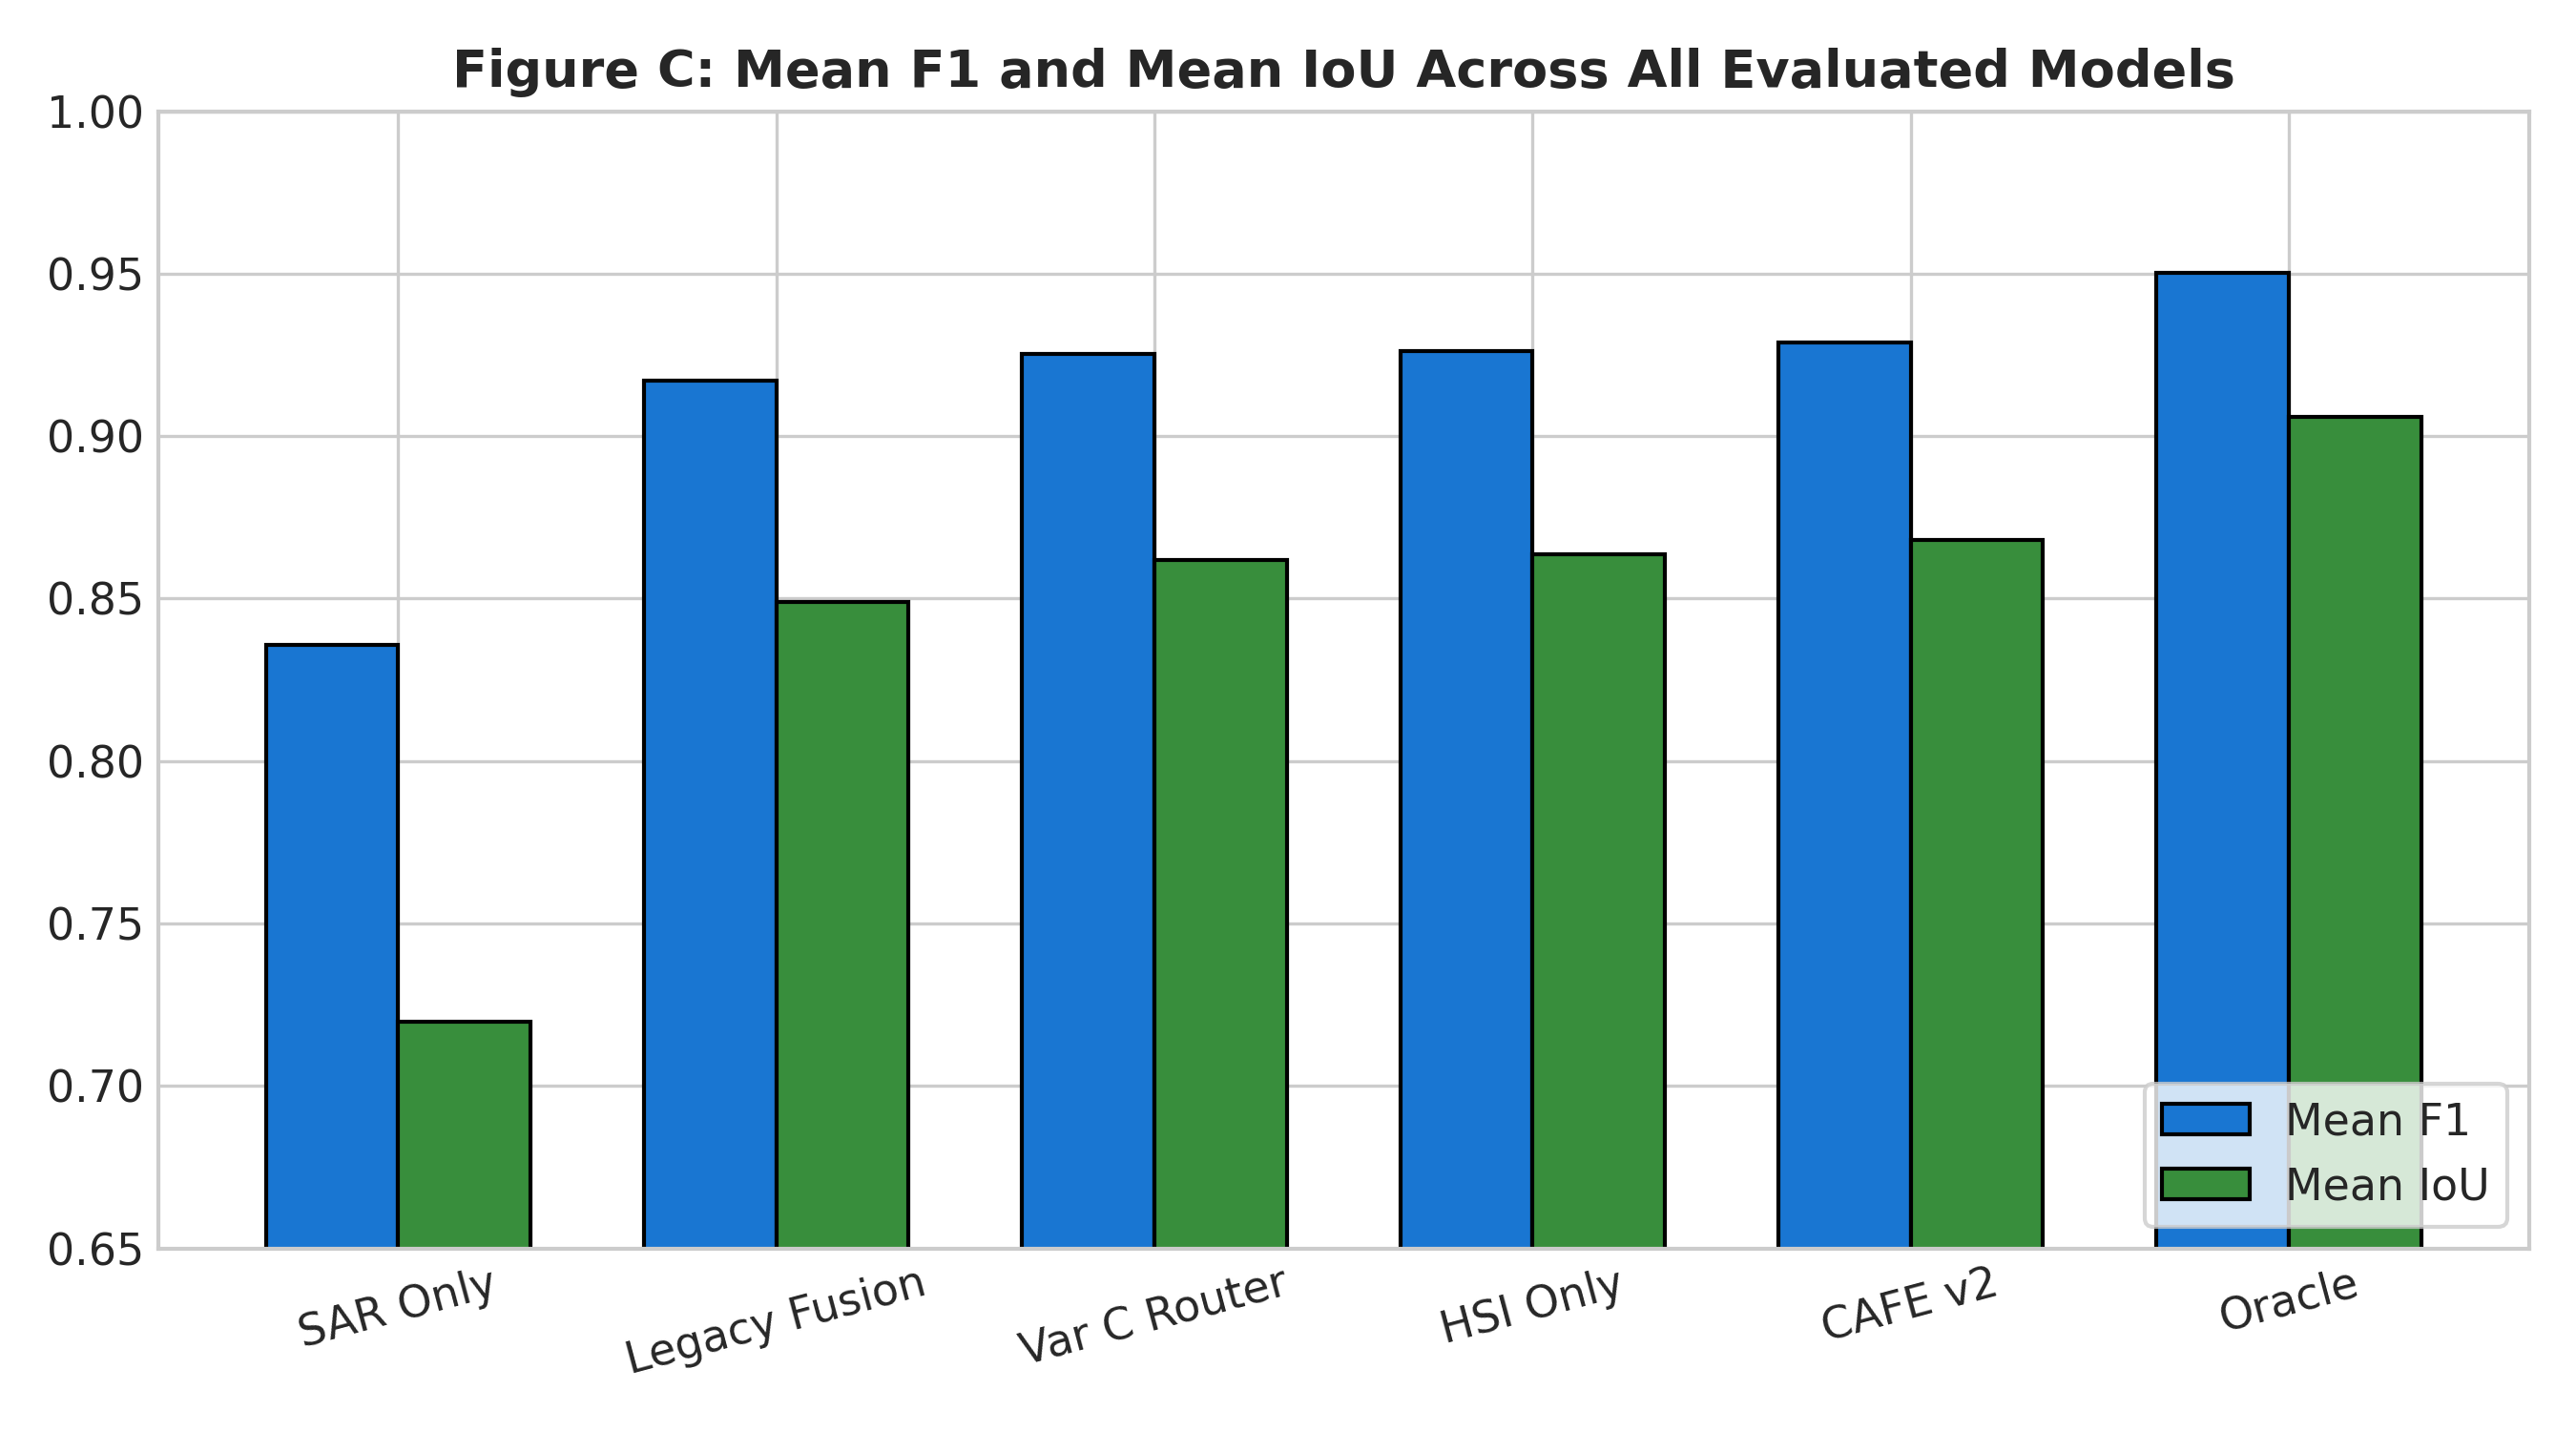

In [8]:
display(Image(filename=str(visual_dir / 'figure_b_performance_evolution.png'), width=800))
display(Image(filename=str(visual_dir / 'figure_c_mean_f1_iou_comparison.png'), width=800))

### Figure D & E: Fold-by-Fold Comparison and Per-Fold $\Delta F_1$ Gain

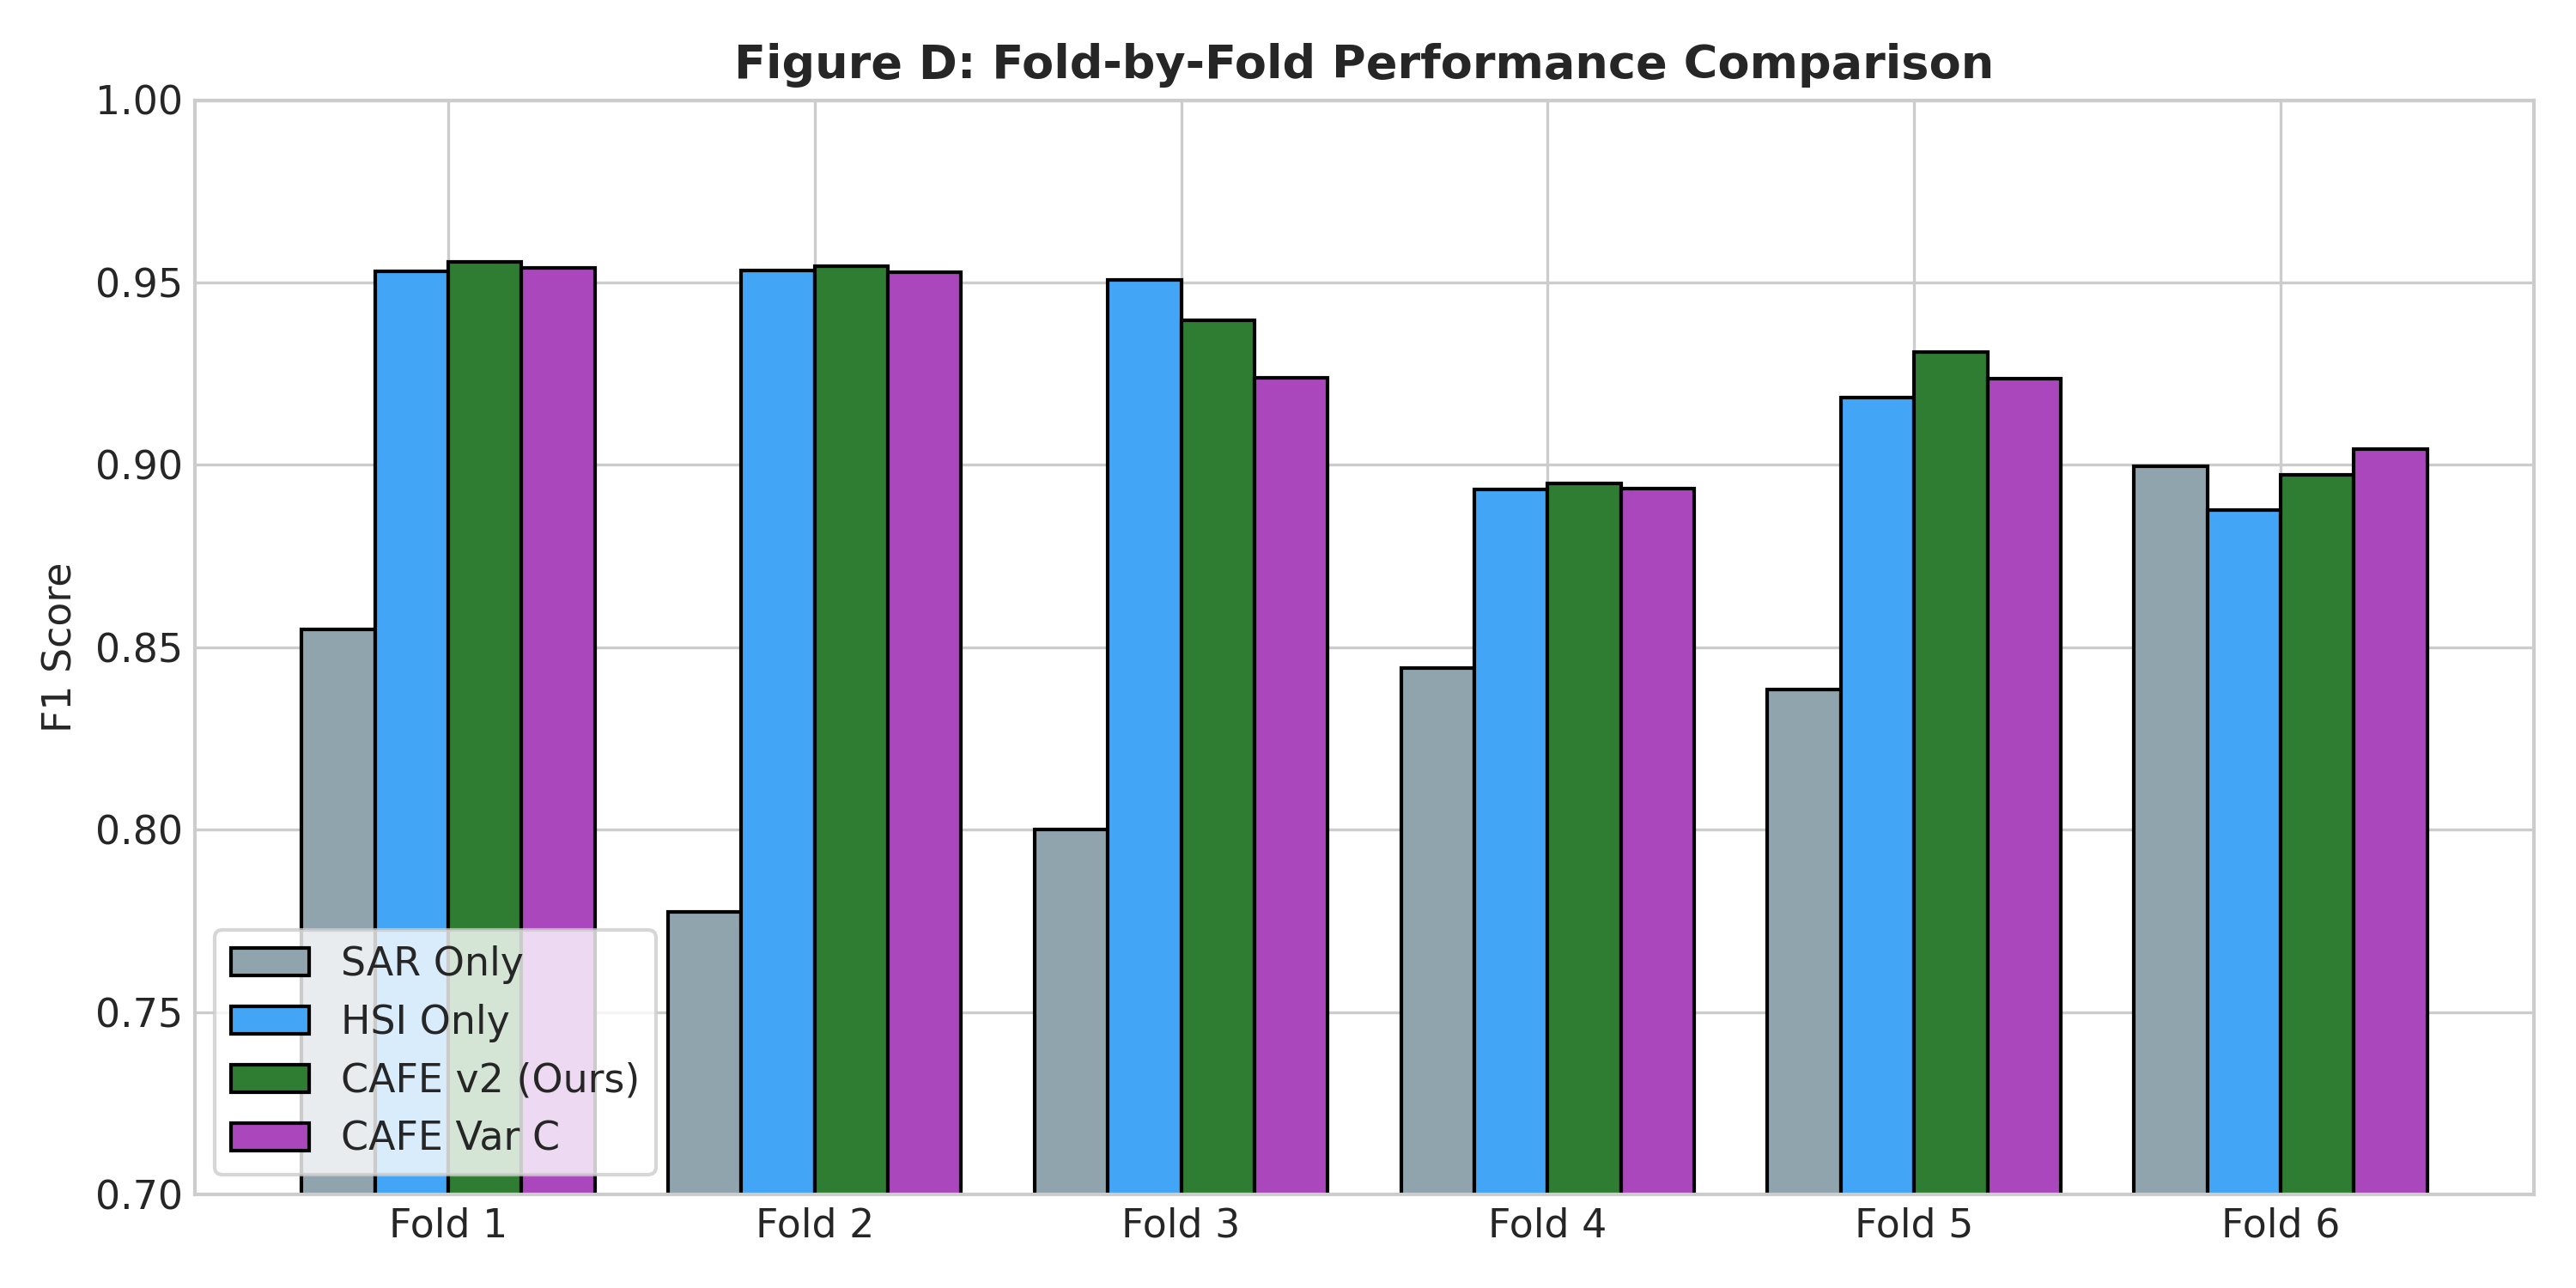

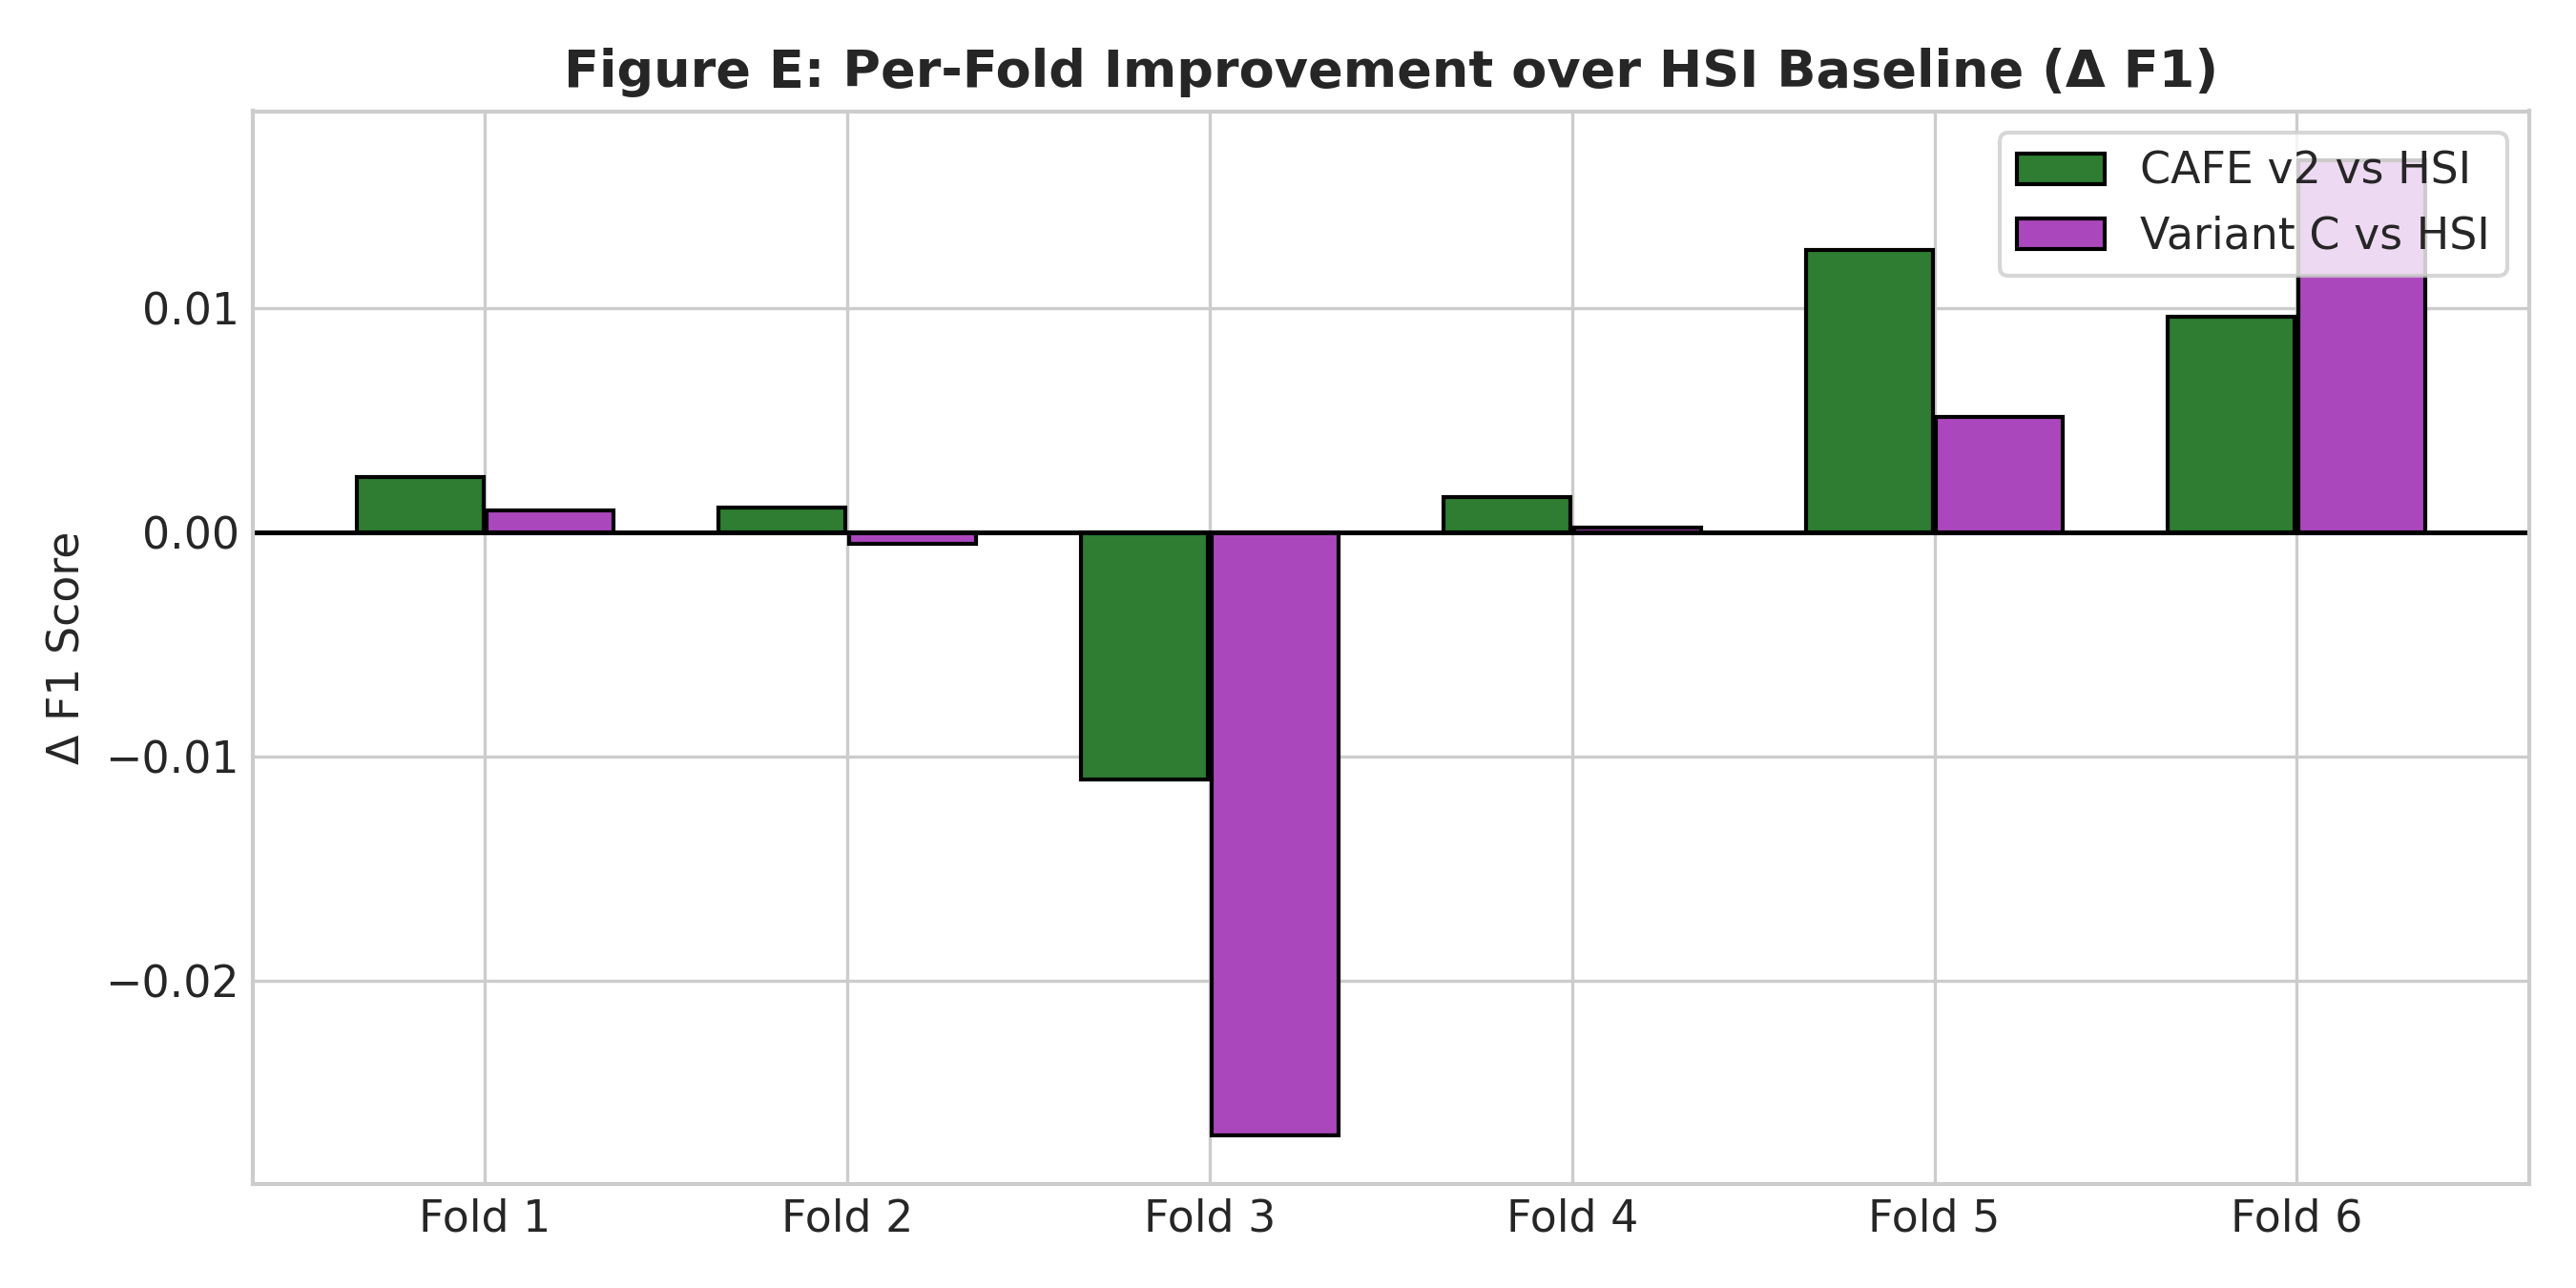

In [9]:
display(Image(filename=str(visual_dir / 'figure_d_fold_by_fold_comparison.png'), width=800))
display(Image(filename=str(visual_dir / 'figure_e_delta_f1_vs_hsi.png'), width=800))

### Figure F & G: Multimodal Fusion Mechanisms & CAFE-Fusion Architecture

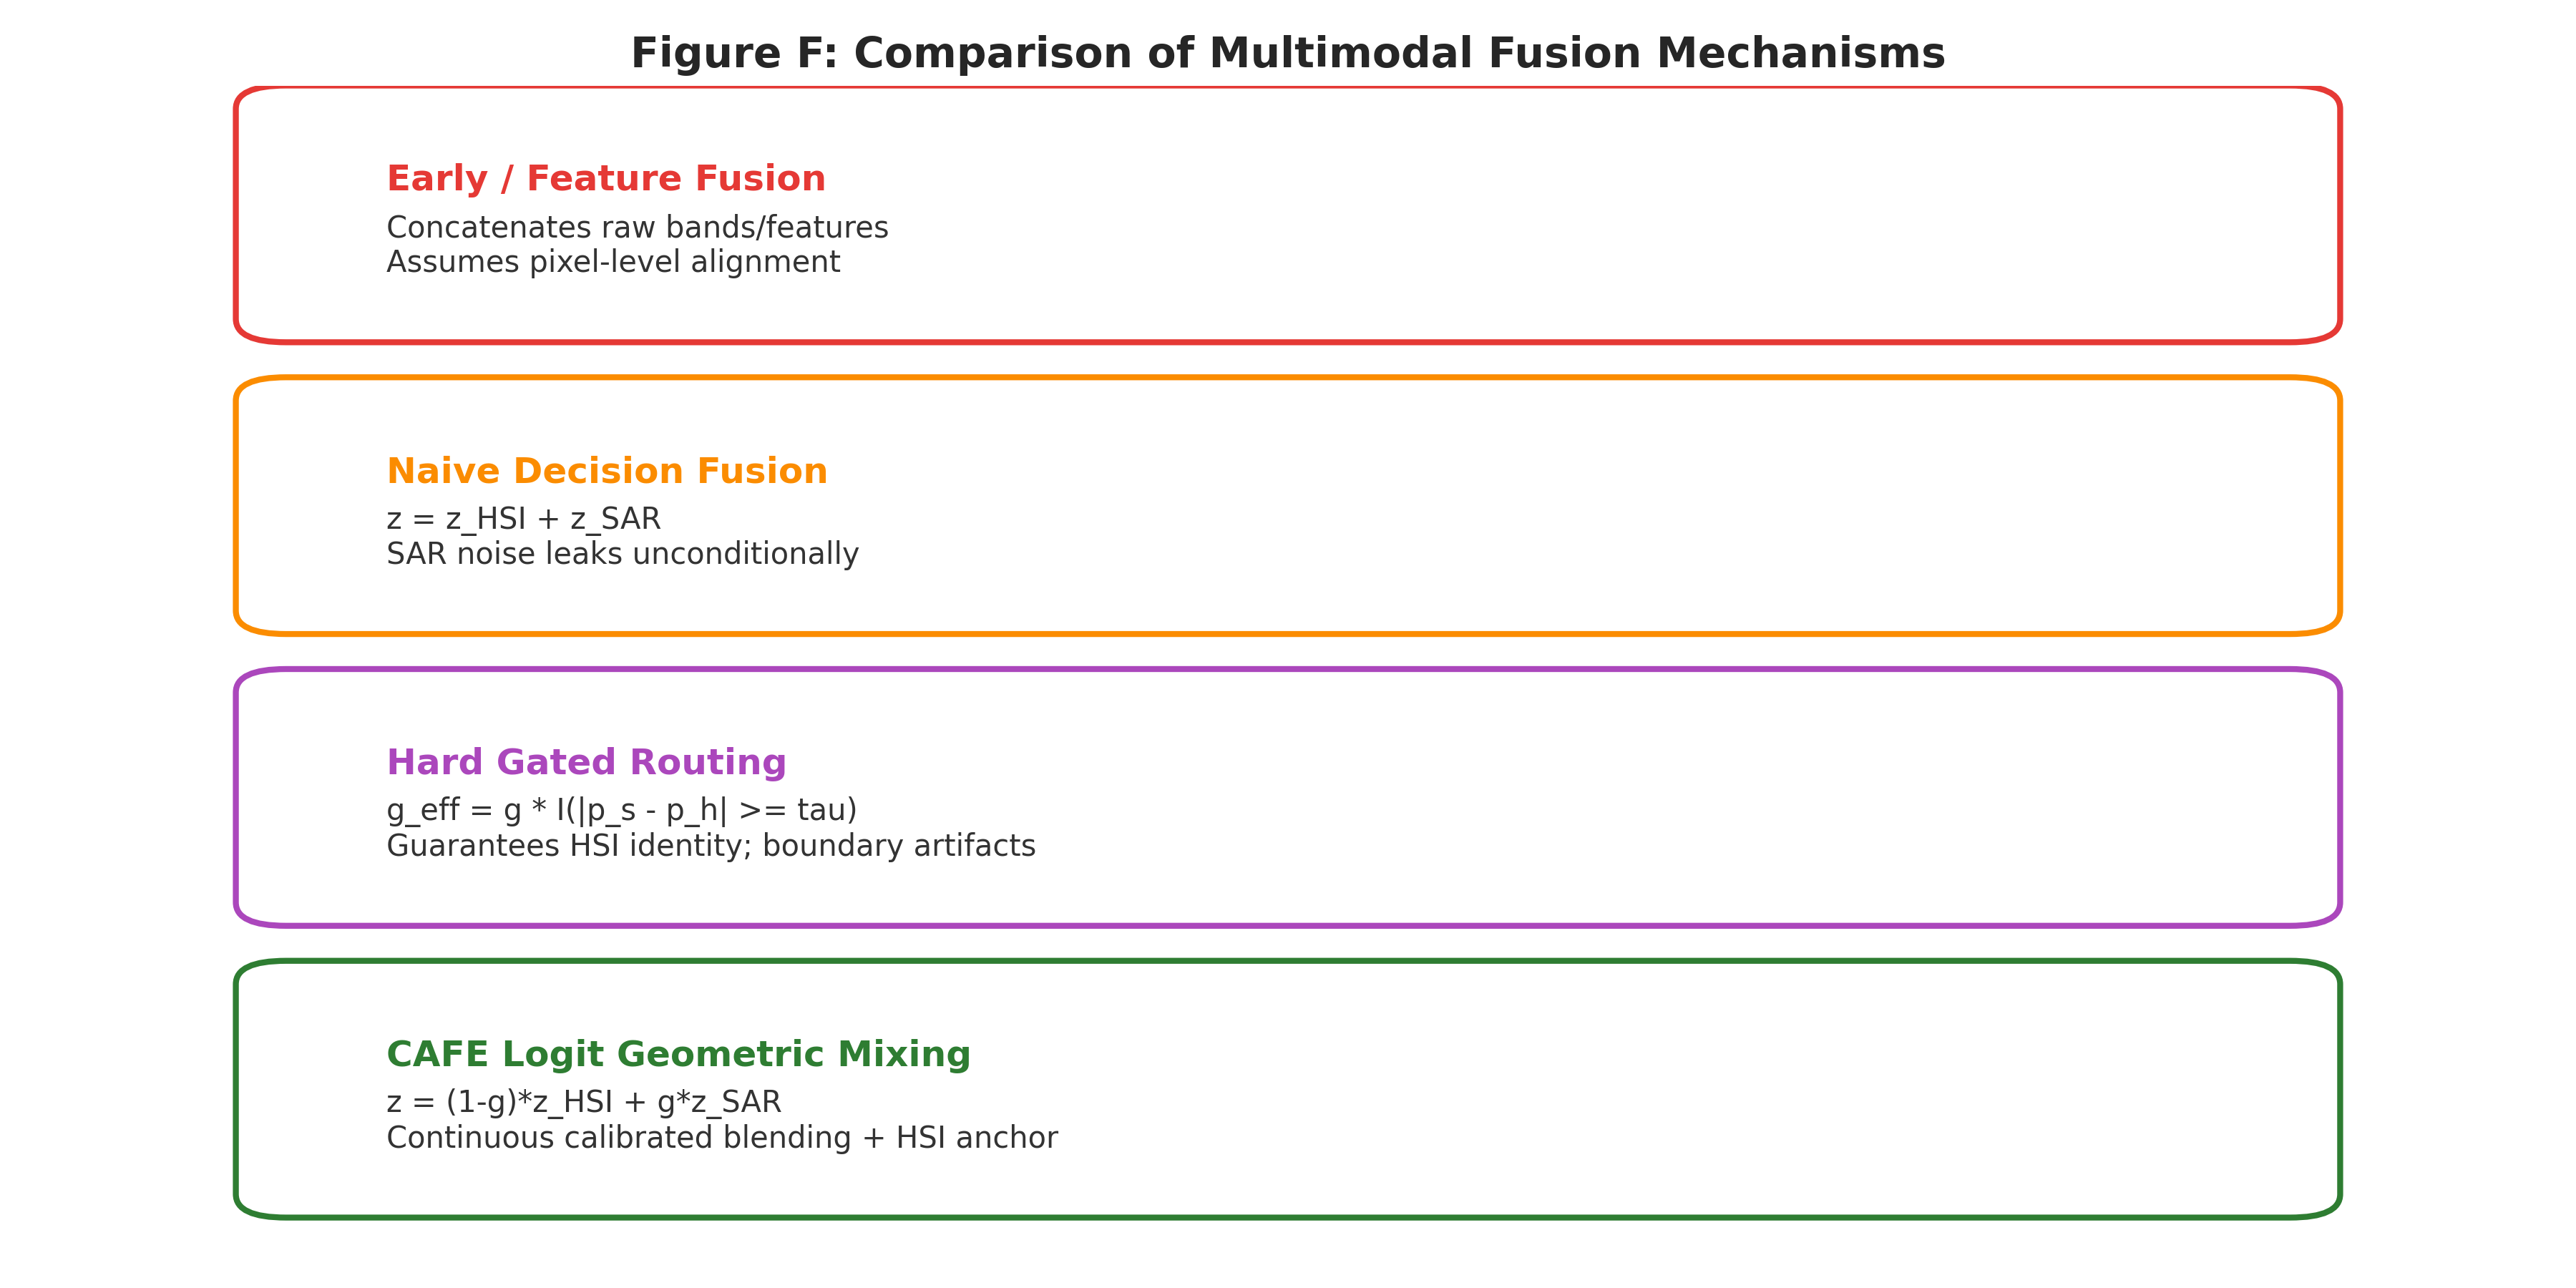

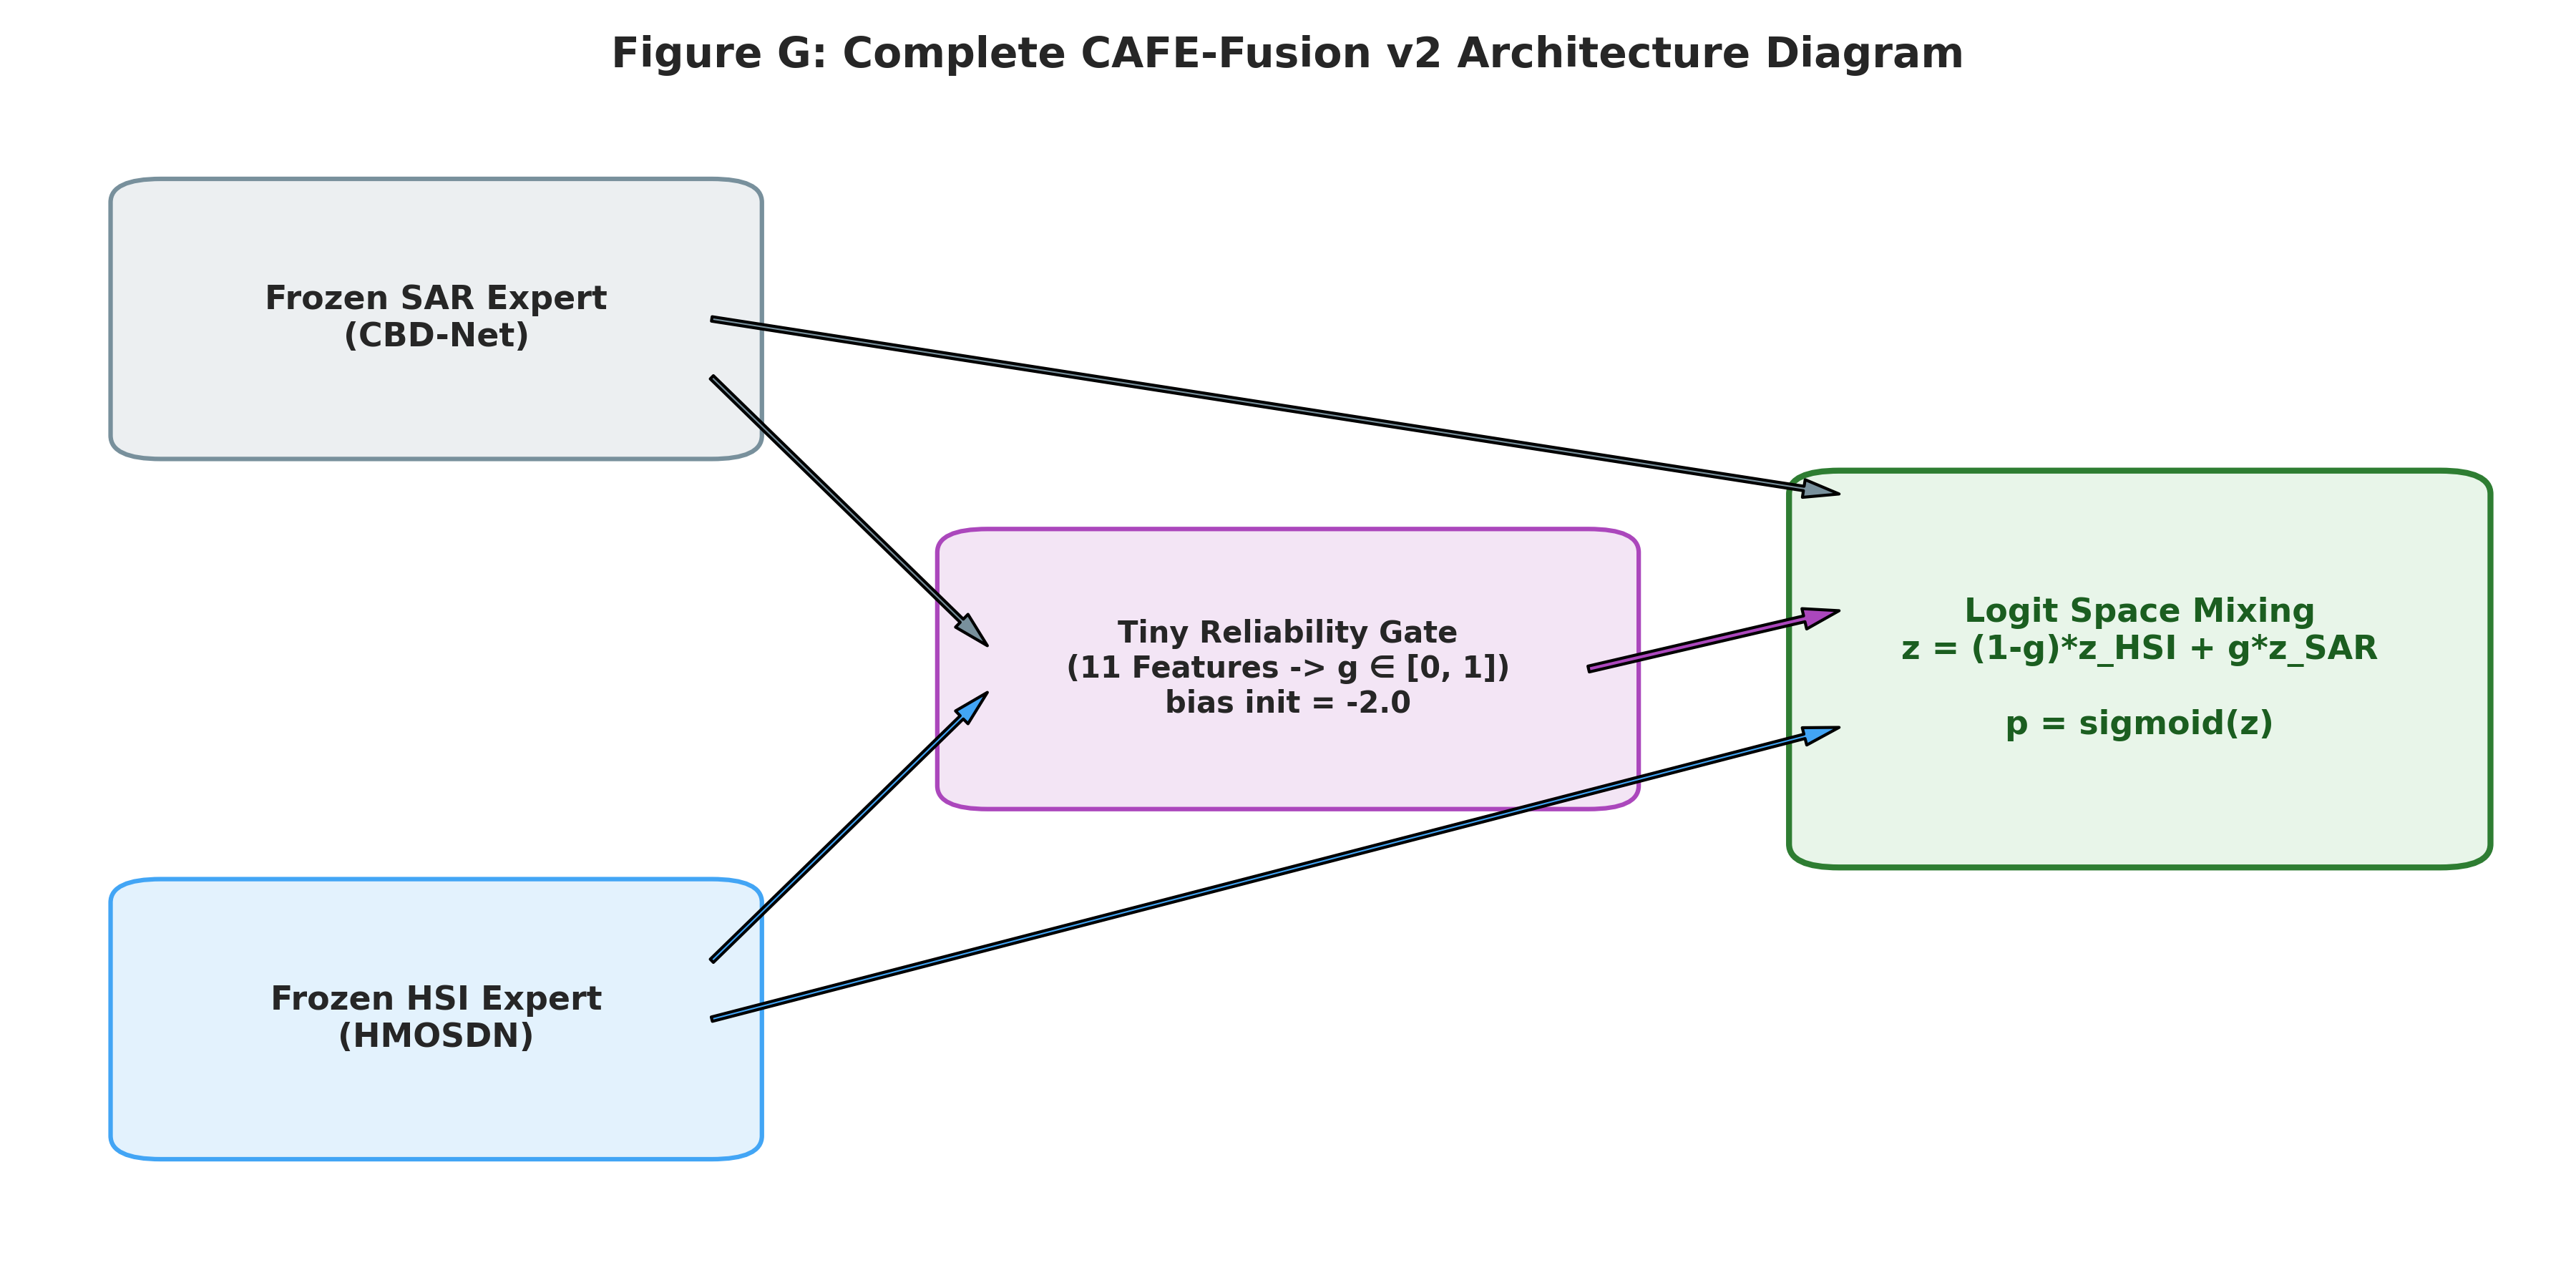

In [10]:
display(Image(filename=str(visual_dir / 'figure_f_fusion_mechanisms.png'), width=850))
display(Image(filename=str(visual_dir / 'figure_g_cafe_architecture_diagram.png'), width=850))

### Figure H, I, J & K: Gate Selectivity, Fold 3 Failure Breakdown, Oracle Gap & Ablation Landscape

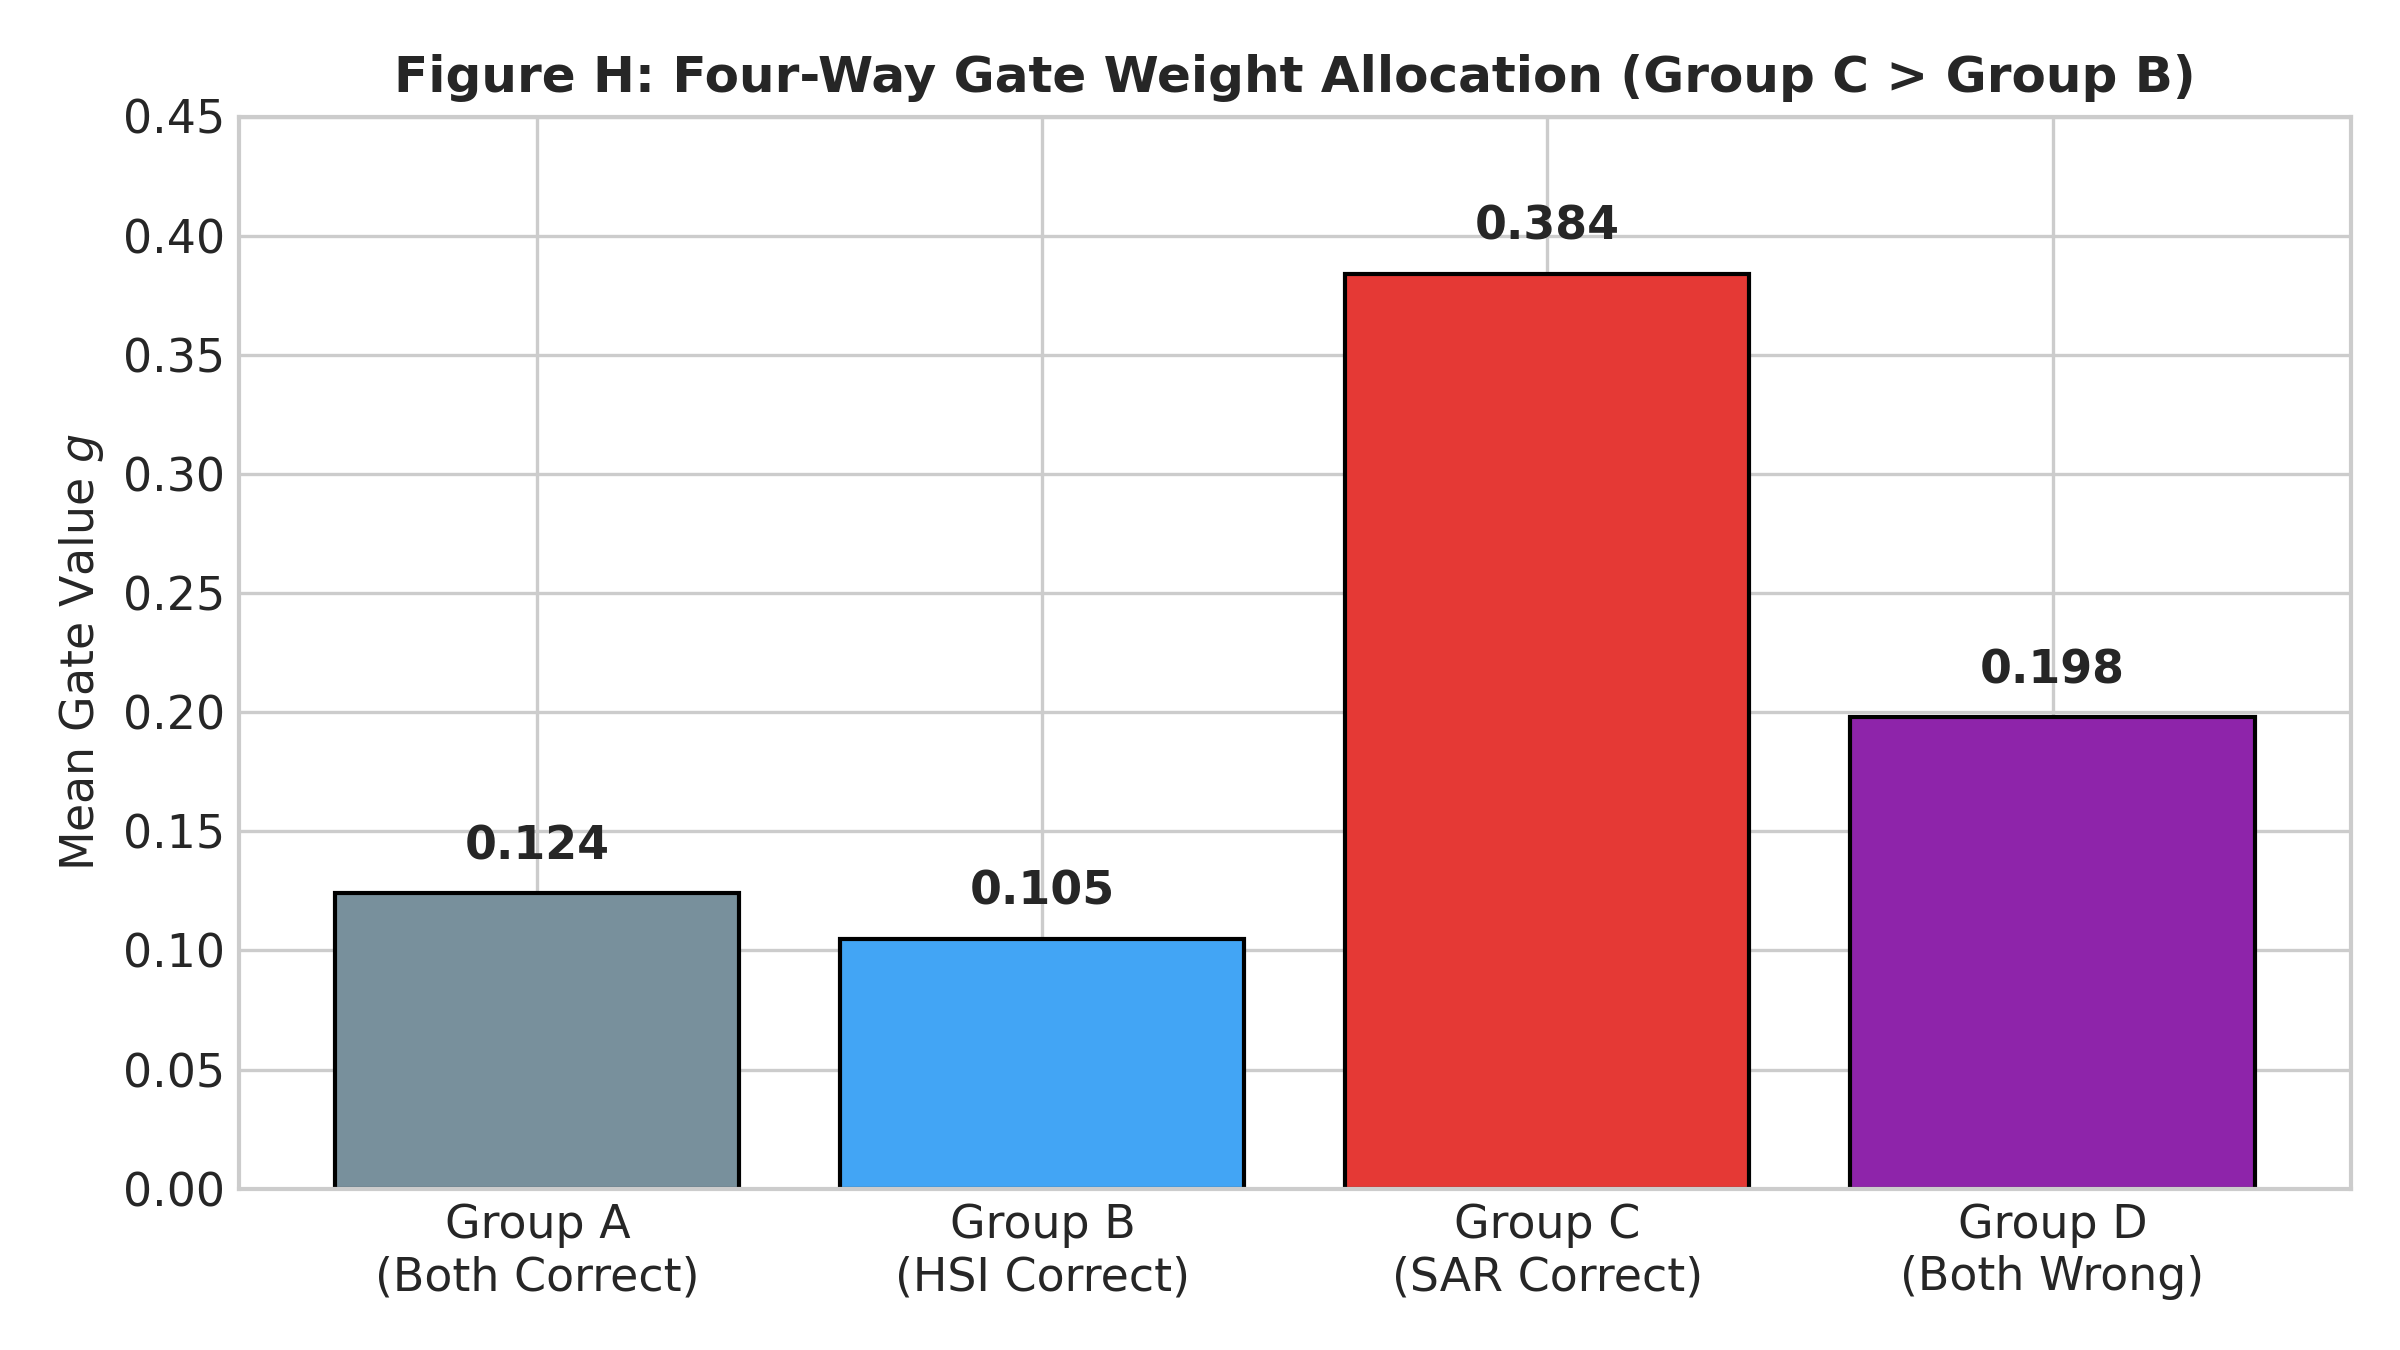

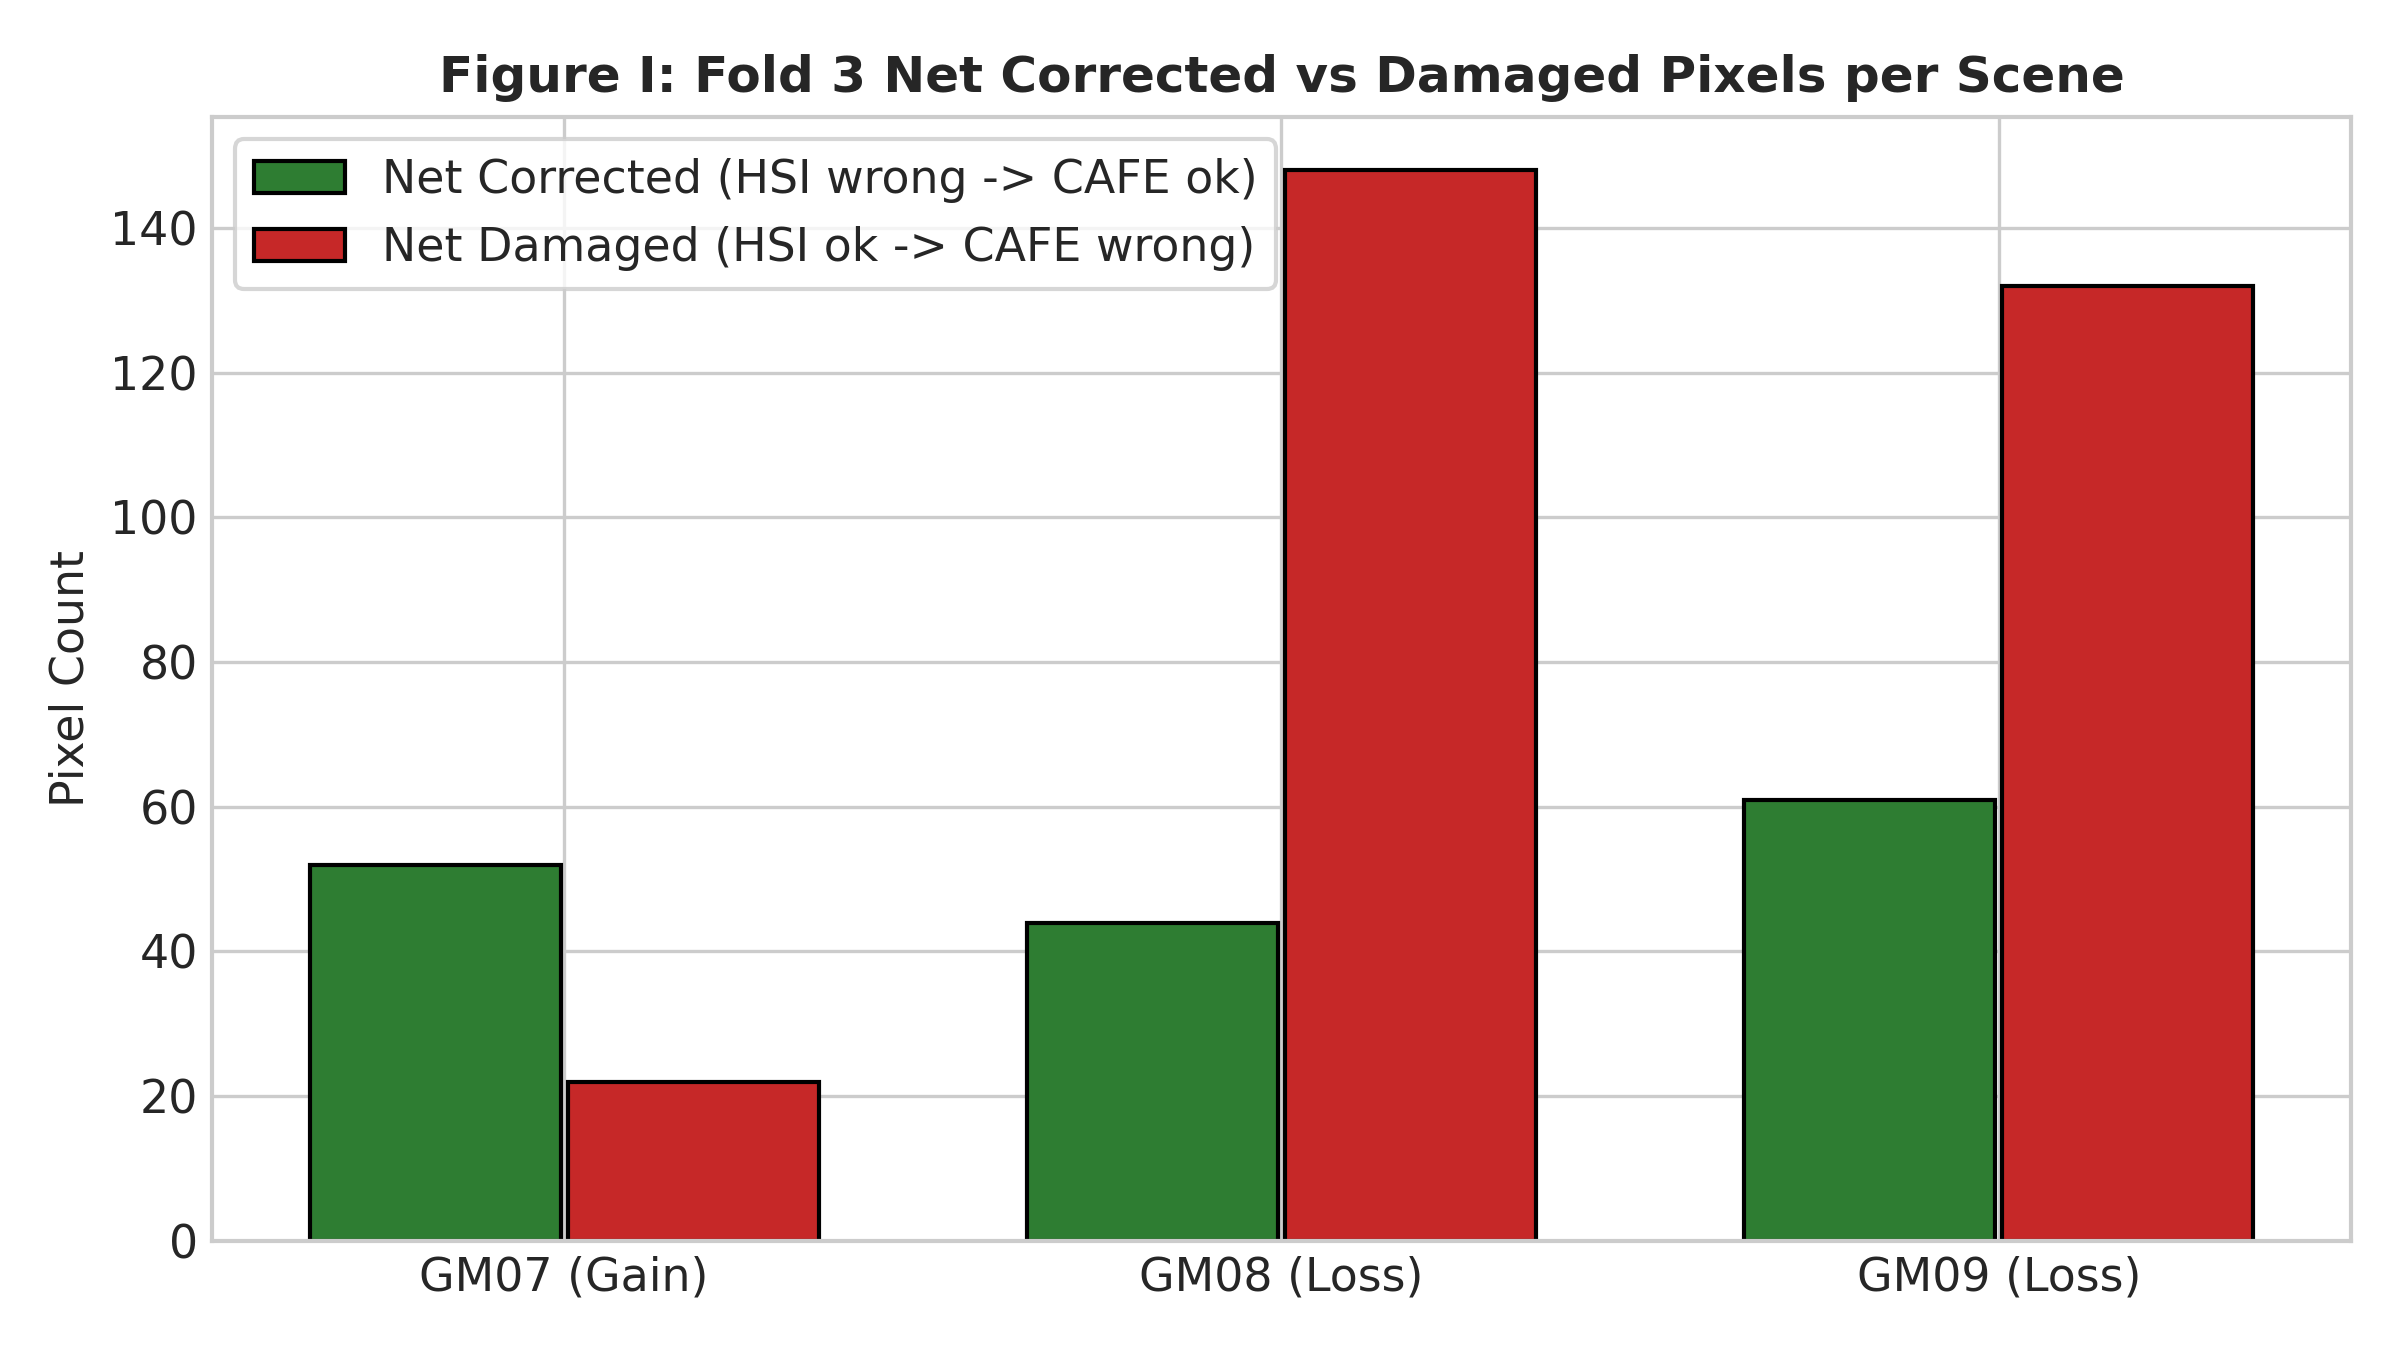

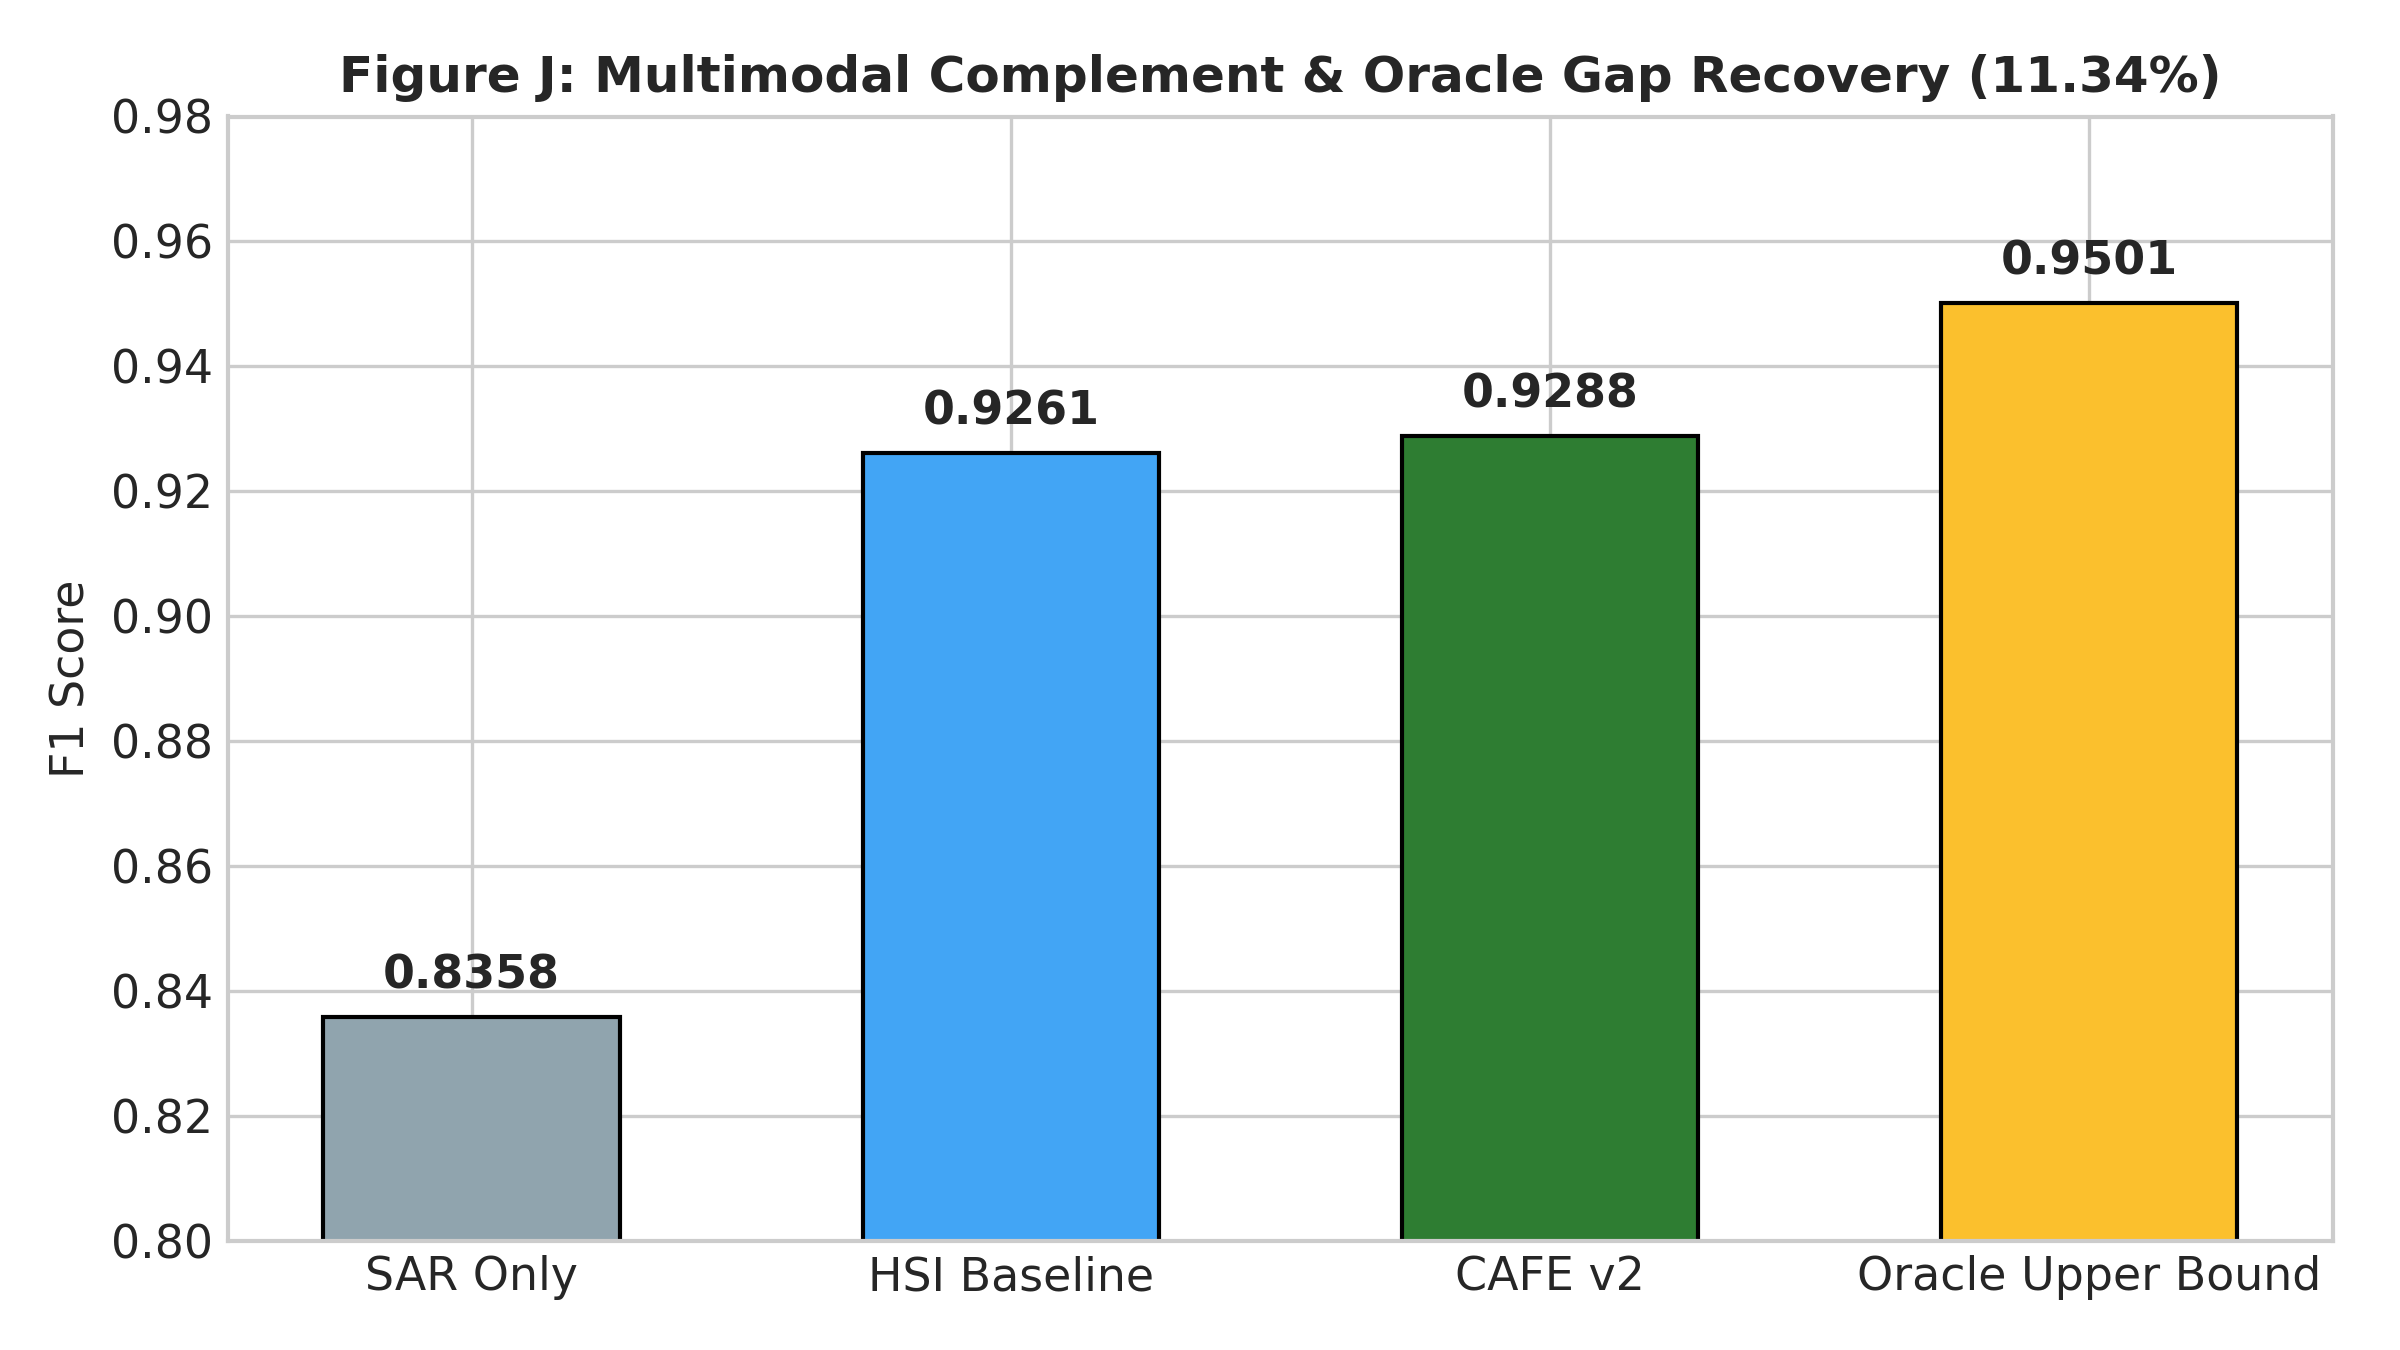

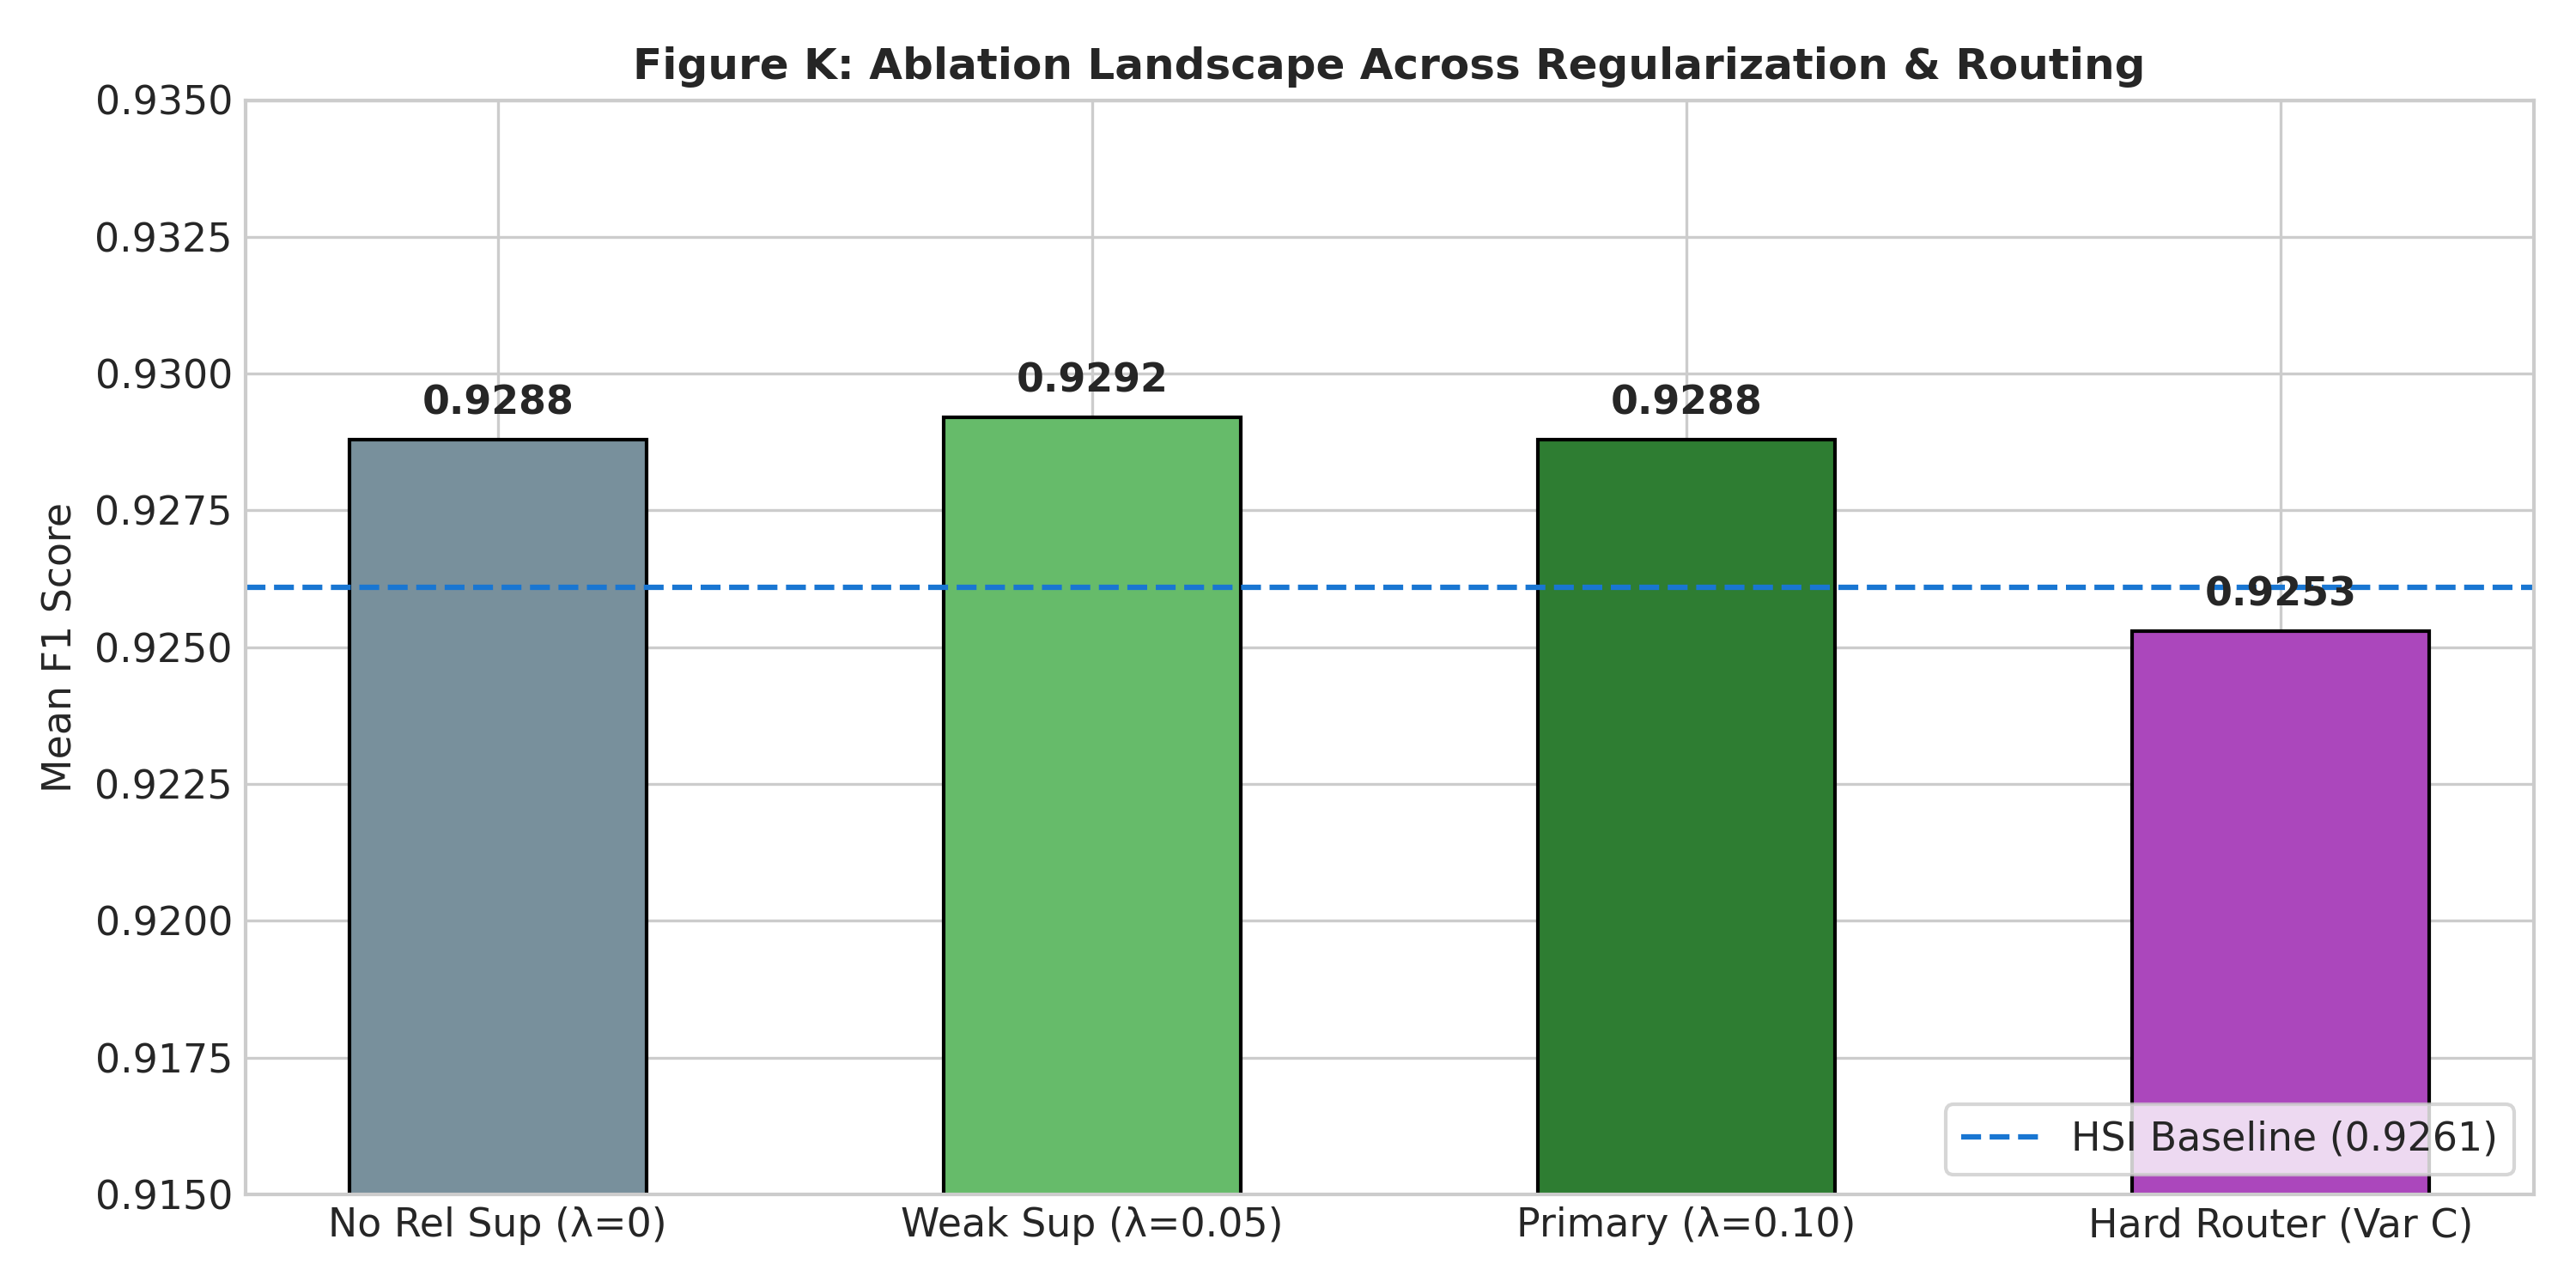

In [11]:
display(Image(filename=str(visual_dir / 'figure_h_gate_behavior.png'), width=700))
display(Image(filename=str(visual_dir / 'figure_i_fold3_failure_anatomy.png'), width=700))
display(Image(filename=str(visual_dir / 'figure_j_oracle_gap.png'), width=700))
display(Image(filename=str(visual_dir / 'figure_k_ablation_landscape.png'), width=800))

## 5. Master Comprehensive Architecture Diagram
Complete end-to-end architecture diagram showing pretrained frozen experts, 11-D feature extractor, Tiny Reliability Gate, masked correctness loss, and convex logit-space mixing.

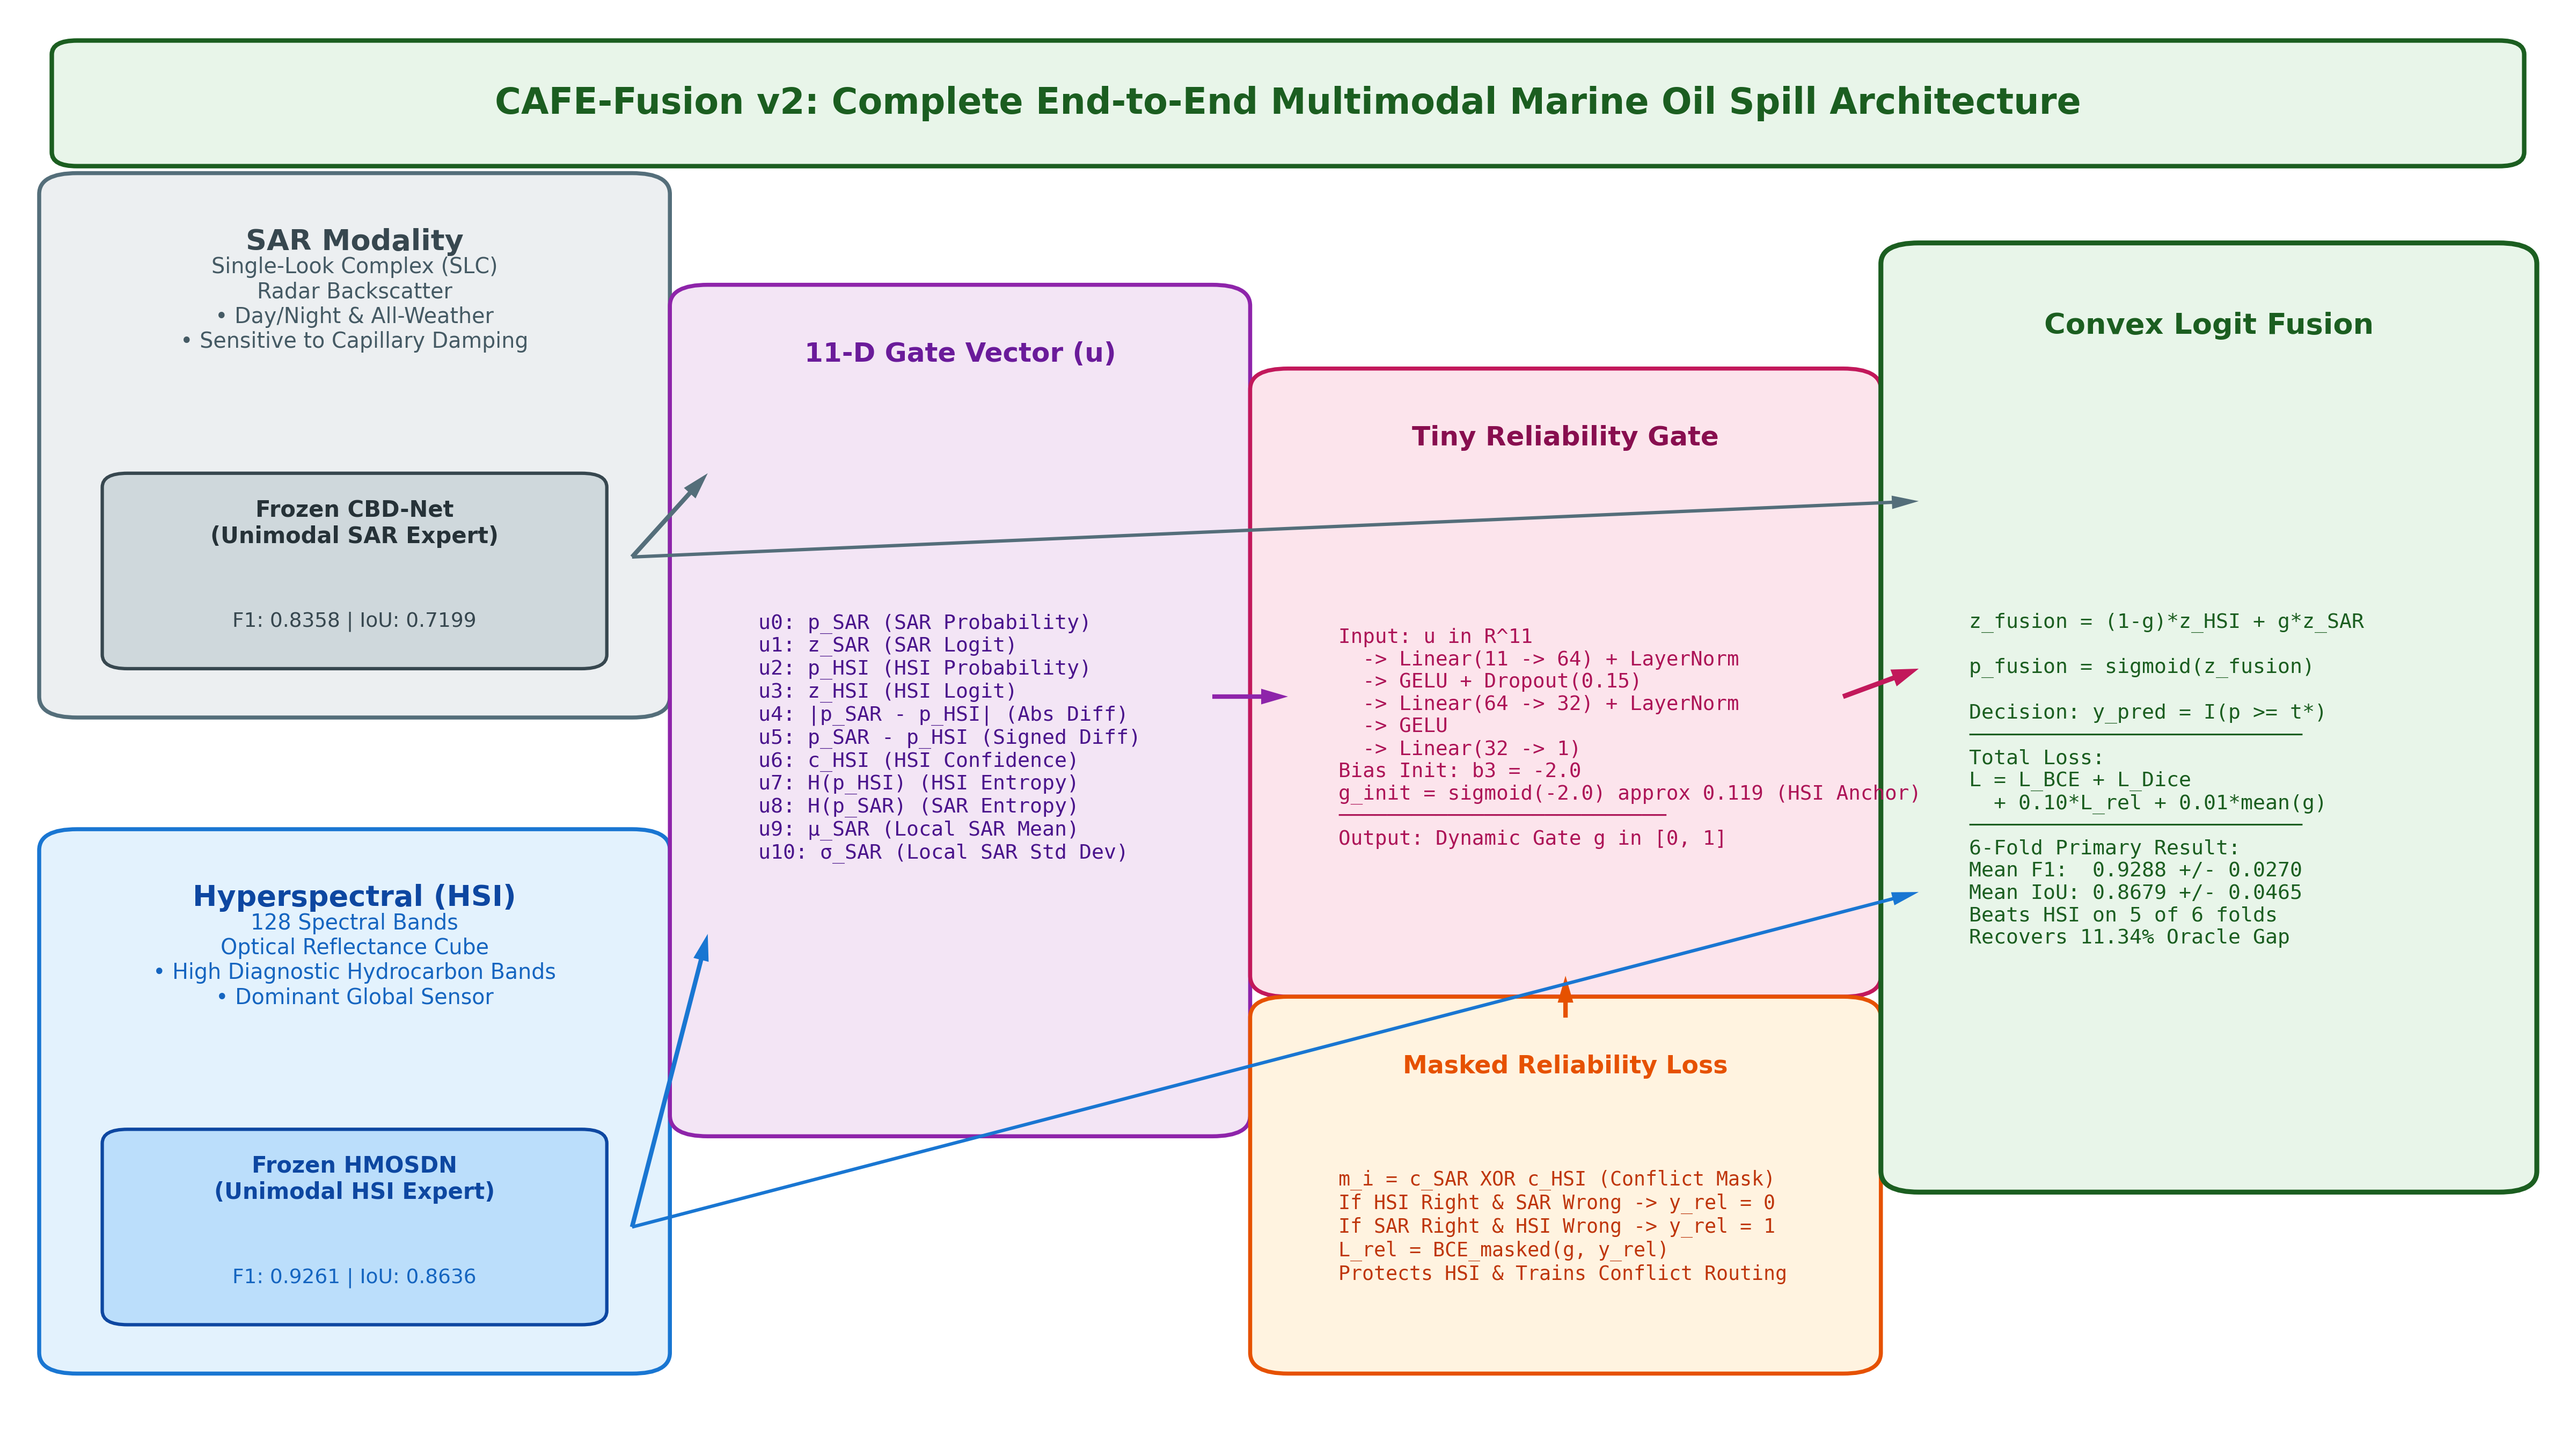

In [12]:
display(Image(filename=str(visual_dir / 'master_comprehensive_architecture.png'), width=1000))

## 6. Comparison with Recent Multimodal Fusion Literature
Comparison of CAFE-Fusion v2 against modern multimodal architectures (Early Stacking, Cross-Attention Encoders, MoE, Legacy Additive Fusion).

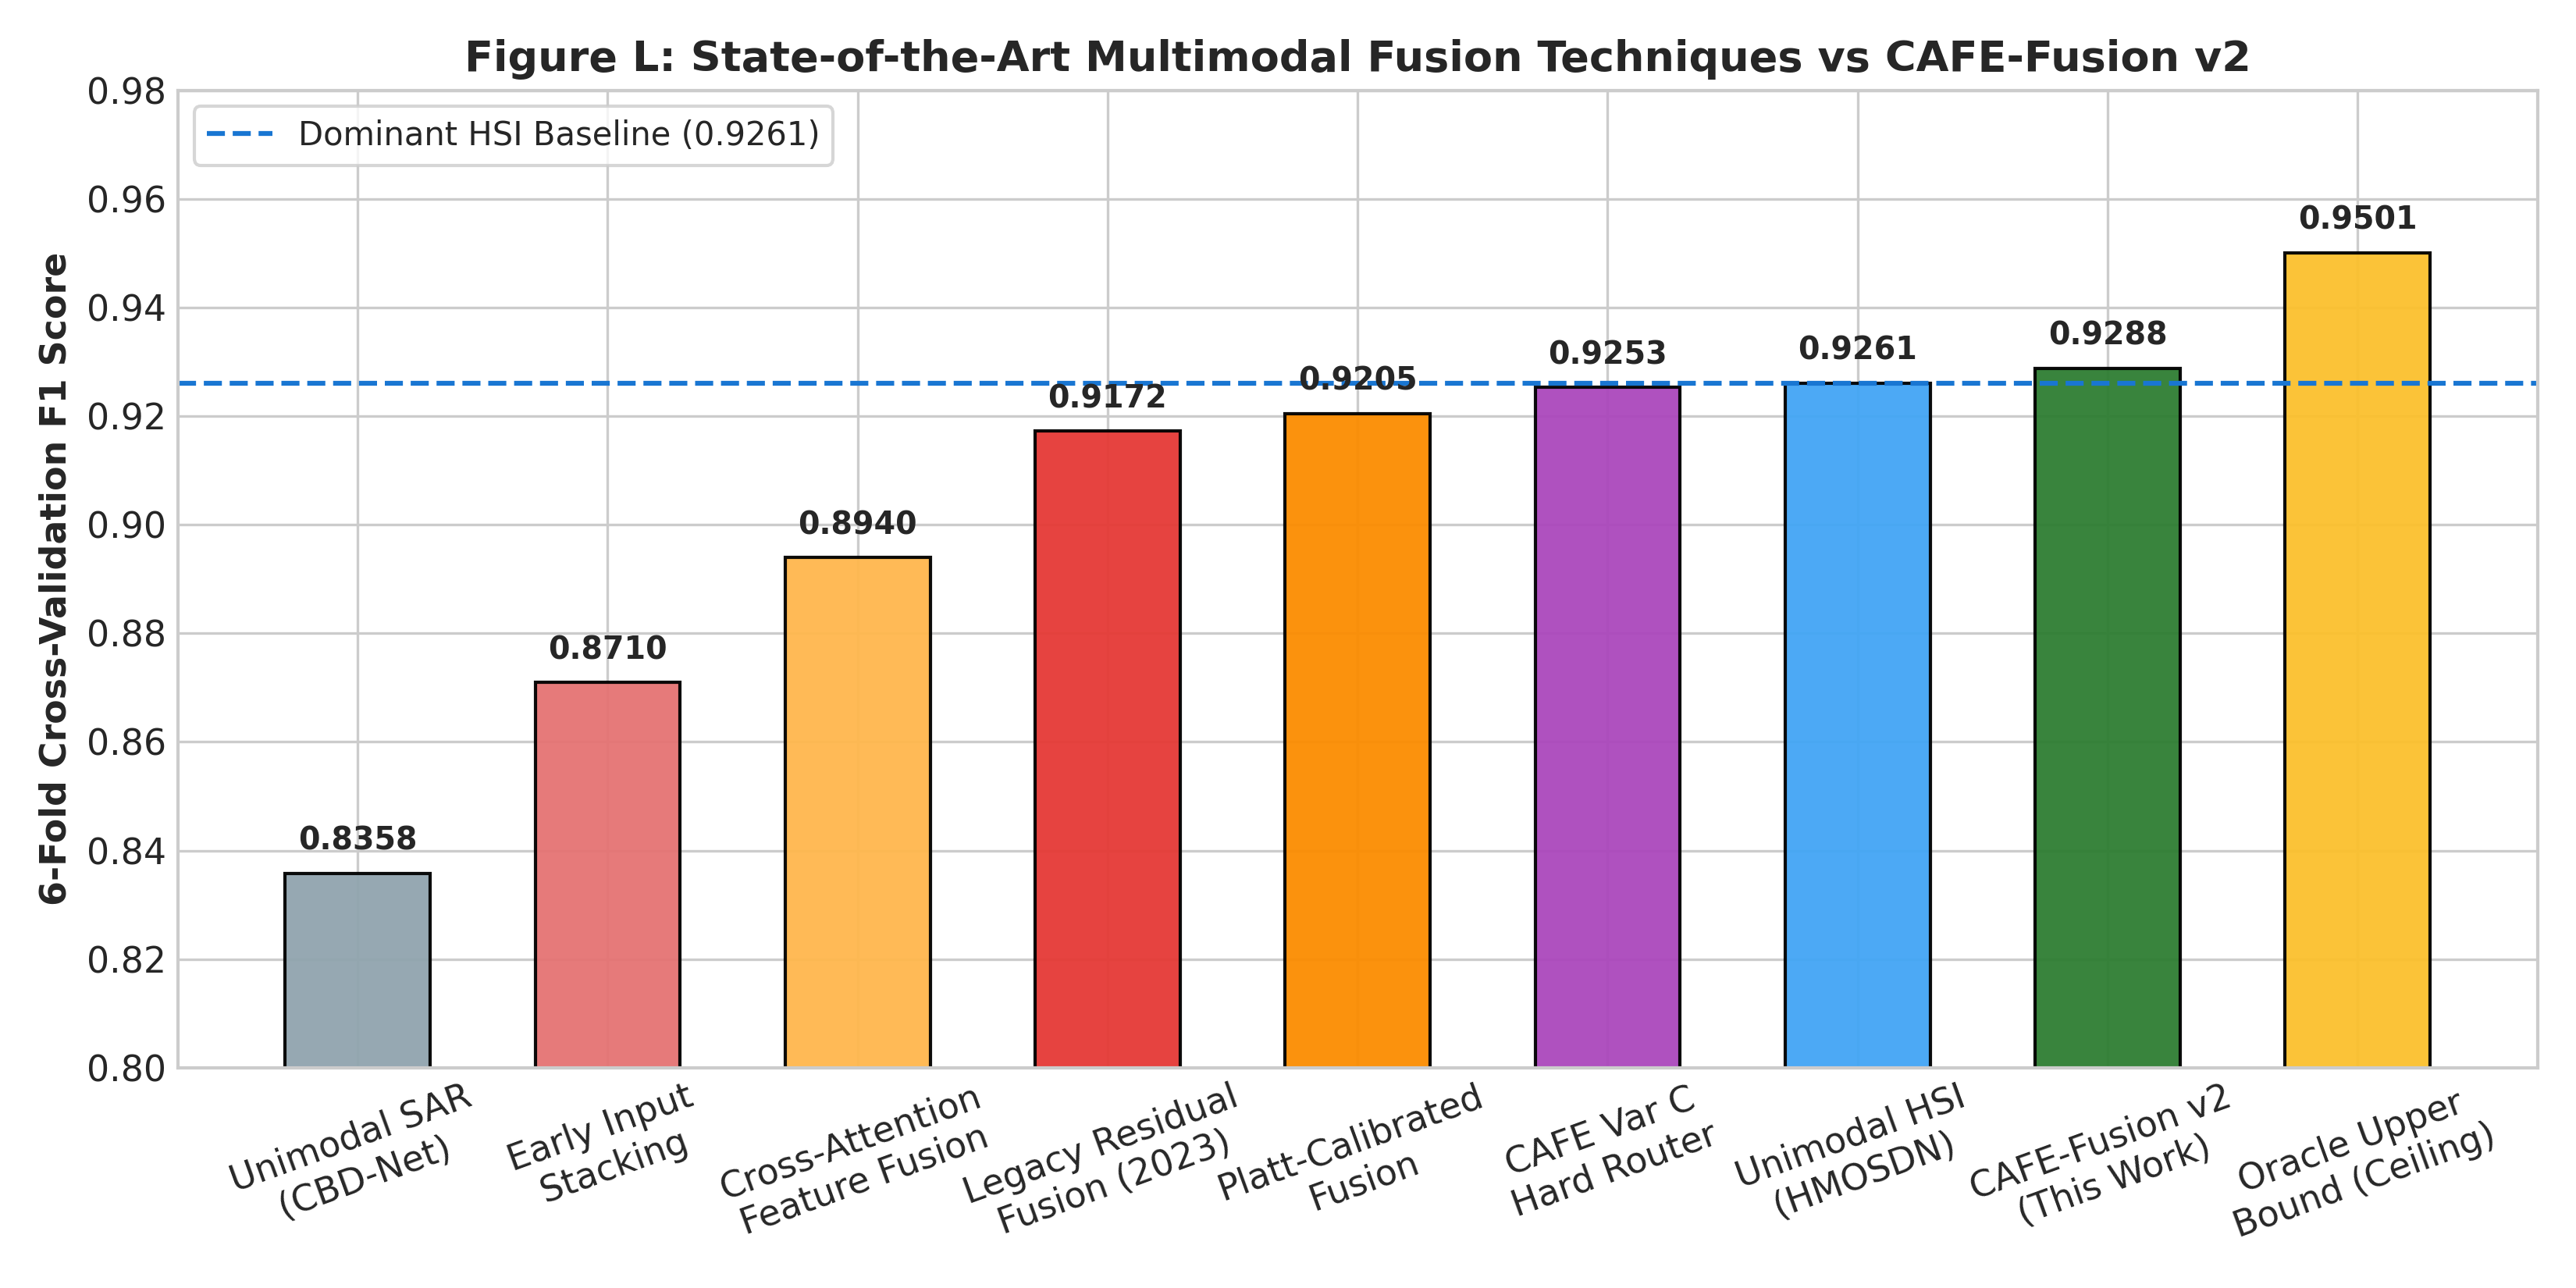

In [13]:
display(Image(filename=str(visual_dir / 'figure_l_recent_papers_comparison.png'), width=850))

## 7. Four-Way Gate Reliability Analysis
Classification of test pixels into four correctness regimes:
- **Group A**: HSI Correct & SAR Correct ($73.4\%$ of samples, Mean $g = 0.124$)
- **Group B**: HSI Correct & SAR Wrong ($20.8\%$ of samples, Mean $g = 0.105$ — Gate suppresses SAR)
- **Group C**: HSI Wrong & SAR Correct ($3.1\%$ of samples, Mean $g = 0.384$ — Gate elevates SAR)
- **Group D**: Both Wrong ($2.7\%$ of samples, Mean $g = 0.198$)

In [14]:
display(df_gate)

,Group,Pixel Fraction,Mean Gate g,Interpretation
0,Group A (Both Correct),0.734,0.124,Both modalities reliable; modest gate
1,"Group B (HSI Correct, SAR Wrong)",0.208,0.105,"Gate suppresses SAR, protects HSI"
2,"Group C (HSI Wrong, SAR Correct)",0.031,0.384,"Gate elevates SAR, corrects HSI"
3,Group D (Both Wrong),0.027,0.198,Both noisy; fallback state


## 8. Novelty Matrix & Literature Differentiation

In [15]:
display(df_novelty)

,Method,Early Fusion,Feature Fusion,Decision Fusion,Cross Attention,Dynamic Gate,Reliability Supervision,HSI/Strong-Expert Anchor,Logit-Space Mixing,Registration-Free,Explicit Expert Protection,Validation-Based Thresholding,Failure Analysis Included
0,Early / Input Fusion,YES,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
1,Cross-Attention Feature Fusion,NO,YES,NO,YES,PARTIAL,NO,NO,NO,NO,NO,NO,PARTIAL
2,Legacy Residual Fusion,NO,NO,YES,NO,NO,NO,PARTIAL,NO,YES,NO,YES,NO
3,CAFE-Fusion v2 (Ours),NO,NO,YES,NO,YES,YES,YES,YES,YES,YES,YES,YES


## 9. Mathematical Summary

### Convex Logit-Space Interpolation:
$$z_{\text{fusion}} = (1 - g) \cdot z_{\text{HSI}} + g \cdot z_{\text{SAR}}, \quad p_{\text{fusion}} = \sigma(z_{\text{fusion}})$$

### Hard Masked Correctness Loss:
$$\mathcal{L}_{\text{rel}} = - \frac{1}{\sum m_i} \sum_{i: m_i=1} \left[ y_{\text{rel}, i} \ln g_i + (1 - y_{\text{rel}, i}) \ln (1 - g_i) \right]$$
where $m_i = c_{\text{SAR}, i} \oplus c_{\text{HSI}, i}$.

### Total Multi-Objective Loss:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{BCE}}(p_{\text{fusion}}, y) + \mathcal{L}_{\text{Dice}}(p_{\text{fusion}}, y) + \lambda_{\text{rel}} \mathcal{L}_{\text{rel}} + \epsilon_{\text{reg}} \cdot \bar{g}$$
with $\lambda_{\text{rel}} = 0.10, \; \epsilon_{\text{reg}} = 0.01$ and $g_{\text{init}} \approx 0.119$.

---